# Efekt rabatu w Nordvik: czy promocje się opłacają?

## 1. Metadata & Purpose

| | |
|---|---|
| **Autor** | agent AI (materiał szkoleniowy; dane syntetyczne) |
| **Data** | 2026-11-10 |
| **Zespół / odbiorca** | dyrektor ds. cen i promocji, Nordvik |
| **Dane** | wyciąg z hurtowni: sprzedaż 2025-01-01 … 2026-09-20 i zwroty przyjęte do 2026-09-20 (szczegóły w sekcji Load Data) |
| **Status** | w toku: ukończone Fazy 1-3 (zlecenie, audyt danych i kalendarz akcji, eksploracja). Kolejne sekcje (hipotezy, metody, odporność, wynik dla biznesu) dopisywane w następnych krokach |

**Firma.** Nordvik to polska sieć odzieżowa z własną marką: 5 sklepów stacjonarnych (Warszawa Arkadia, Warszawa Mokotów, Kraków Rynek, Poznań, Gdańsk) i sklep internetowy. Sprzedaje siedem kategorii (Kurtki, Sukienki, Swetry, Jeansy, T-shirty, Koszule, Akcesoria). Jeden *model* (kod `StyleCode`) występuje w kilku kolorach i rozmiarach; pojedyncza kombinacja model x kolor x rozmiar to *SKU*. Rok dzieli się na sezony: `SS` (luty-lipiec) i `AW` (sierpień-styczeń). Waluta: PLN, VAT 23%. Według opisu firmy typowy cykl ceny produktu to: pełna cena, po ok. 8 tygodniach rabat sezonowy -20…-30% (2-3 tygodnie), potem wyprzedaż -40…-60%; do tego Black Friday i kilka akcji na wybrane kategorie. To deklaracja firmy, w danych sprawdzam, co faktycznie się działo.

**Zlecenie biznesowe (własnymi słowami).** Dyrektor ds. cen i promocji widzi, że w tygodniach z rabatem sprzedaż rośnie. Nie wie jednak, ile z tego wzrostu zrobił rabat, a ile wynika z tego, że to i tak okres, w którym wszyscy kupują (listopadowy Black Friday z rabatem 20%, grudzień, wyprzedaże końca sezonu). Firma nie ma spisanego kalendarza akcji z ostatnich 20 miesięcy. Pytania:

1. Czy dodatkowa sprzedaż pokrywa utraconą marżę?
2. Czy kategorie reagują na rabat tak samo (podejrzenie: jeansy mocniej niż kurtki)?
3. Czy część wzrostu to tylko przesunięcie zakupów z następnych tygodni?

**Decyzja do podjęcia:** kalendarz akcji na sezon AW26 (listopad 2026 - styczeń 2027): które kategorie, jak głęboki rabat, czy w ogóle. Odpowiedź potrzebna za 2 tygodnie.

**Hipotezy i wyniki** zostaną wpisane tu po ich sformułowaniu (Faza 4) i po obliczeniach; na tym etapie notebook kończy się eksploracją.

### Słowniczek pojęć używanych w notebooku
(każde pojęcie jest też wyjaśnione krótko przy pierwszym użyciu)

- **Kontrfakt**: sprzedaż, która byłaby w tym samym czasie i miejscu *bez* rabatu. Nigdy jej nie obserwujemy, można ją tylko oszacować. Efekt rabatu = obserwowana sprzedaż minus kontrfakt.
- **Uplift**: względny wzrost sprzedaży (w sztukach) dzięki rabatowi, w porównaniu z kontrfaktem. Uplift 50% = o połowę więcej sztuk niż bez rabatu.
- **Elastyczność cenowa**: o ile procent zmienia się sprzedaż (w sztukach) przy zmianie ceny o 1%. Przy elastyczności -2 obniżka ceny o 10% zwiększa sprzedaż o ok. 20%.
- **Próg opłacalności**: o ile procent trzeba zwiększyć sprzedaż w sztukach, żeby przy danej głębokości rabatu marża w złotówkach się nie pogorszyła.
- **Selekcja do leczenia**: rabat dostają nie losowe produkty, tylko wybrane (np. te, które źle się sprzedają). Wtedy proste porównanie produktów z rabatem i bez rabatu miesza efekt rabatu z cechami tych produktów.
- **Przesunięcie popytu** (cannibalization / pull-forward): klienci kupują w trakcie akcji to, co kupiliby w następnych tygodniach po pełnej cenie. Wzrost w trakcie akcji jest wtedy częściowo pozorny.

## 1.1 Faza 1: zrozumienie zlecenia

### Co znaczy „rabat się opłaca"
Zlecenie nie definiuje słowa „opłaca się". Przyjmuję definicję roboczą (do potwierdzenia ze zleceniodawcą, patrz pytania na końcu sekcji):

> Akcja się opłaca, jeśli **marża brutto po zwrotach**, liczona w złotych, w oknie „akcja + 2 tygodnie po akcji" jest **nie niższa** niż w kontrfakcie (ten sam model, te same lokalizacje, ten sam czas, bez rabatu).

Uzasadnienie wyboru wskaźnika wyniku:

| Wskaźnik | Dlaczego tak / nie |
|---|---|
| Sztuki | Dobre do *estymacji* reakcji (liczby całkowite, patrz zera), ale nie mówią nic o pieniądzach: rabat zawsze można „kupić" sztukami |
| Sprzedaż netto | Rabat może zwiększyć obrót, a zmniejszyć zysk; obrót nie uwzględnia kosztu |
| **Marża brutto po zwrotach (PLN)** | To jest to, co firma zarabia. Uwzględnia cenę po rabacie, koszt własny i zwroty (online ok. 18% sztuk, więc nie można ich pominąć) |

- **Jednostka analizy:** model x lokalizacja x tydzień (lokalizacja = sklep lub kanał online). Tydzień = pełny tydzień ISO od poniedziałku do niedzieli. Powód: rabaty są nadawane na modele i obowiązują przez tygodnie, a dzienna sprzedaż pojedynczego SKU jest zbyt rzadka (dużo zer).
- **Kanały osobno:** sklepy stacjonarne i online mają inne zwroty (orientacyjnie 4% vs 18% sztuk) i prawdopodobnie inną reakcję na cenę.
- **Kontrfakt:** „ten sam model w tym samym tygodniu bez rabatu". Szacuję go z (a) modeli/kategorii, które w tym czasie rabatu nie miały, (b) historii tego samego modelu sprzed akcji, (c) znanych wzorców sezonowych. Każdy z tych elementów ma słabość (patrz zagrożenia niżej), dlatego porównam kilka metod.

### Wzór na próg opłacalności
Oznaczenia (na jedną sztukę, wartości netto, czyli bez VAT):

- $p$ = cena katalogowa netto (cena brutto z paragonu / 1,23),
- $c$ = koszt własny jednostkowy ($c < p$),
- $d$ = głębokość rabatu (stopa rabatu, np. 0,2 dla -20%),
- $\rho_0,\ \rho_1$ = odsetek sztuk zwróconych bez rabatu i z rabatem.

**Wersja bez zwrotów.** Marża jednostkowa bez rabatu $m_0 = p - c$, z rabatem $m_1 = p(1-d) - c$. Żeby marża łączna się nie pogorszyła, sprzedaż w sztukach musi wzrosnąć co najmniej tyle razy, ile wynosi $m_0/m_1$:

$$
\text{wymagany uplift} \;=\; \frac{m_0}{m_1} - 1 \;=\; \frac{d}{\,1 - d - k\,}, \qquad k = \frac{c}{p}
$$

gdzie $k$ to udział kosztu własnego w cenie katalogowej netto. Wzór jest ważny tylko dla $d < 1-k$ (przy większym rabacie każda sprzedana sztuka przynosi stratę, więc żaden uplift nie pomoże).

**Wersja ze zwrotami.** Zwrot zwraca klientowi pieniądze. Co dzieje się z towarem, w danych nie wiadomo (brak informacji o ponownej sprzedaży). Dlatego liczę dwa warianty brzegowe:

- **A (konserwatywny, zgodny ze słownikiem metryk):** zwrócony towar jest „odpisany": koszt własny pozostaje. Marża jednostkowa $= p(1-d)(1-\rho) - c$.
- **B (towar wraca na stan i zostaje sprzedany za koszt):** koszt wraca razem ze zwrotem. Marża jednostkowa $= \big(p(1-d) - c\big)(1-\rho)$.

W obu wariantach próg to $m_0/m_1 - 1$ z odpowiednimi $m$ i z $\rho_0 \ne \rho_1$, jeśli zwroty zależą od rabatu (to sprawdzę w Fazie 3).

**Przesunięcie popytu obniża korzyść.** Jeśli część sprzedaży akcji jest „pożyczona" z kolejnych tygodni, to uplift netto = uplift w akcji minus spadek w oknie po akcji (względem kontrfaktu). Porównuję z progiem właśnie uplift **netto**.

### Dlaczego dane obserwacyjne utrudniają odpowiedź
Nikt nie losował, które modele i kiedy dostały rabat. Rabaty są nadawane według reguł biznesowych (kalendarz sezonowy, stan zapasów, ocena modelu), więc:

1. **Czas:** akcje wypadają w okresach, kiedy sprzedaż i tak rośnie (Black Friday, grudzień) albo spada (koniec sezonu). Proste „tydzień z rabatem vs reszta roku" miesza rabat z sezonem.
2. **Selekcja:** wyprzedaże dostają prawdopodobnie modele, które sprzedają się słabo (stare kolekcje). Ich „sprzedaż bez rabatu" byłaby niska, więc regresja po wszystkich modelach może efekt rabatu *zaniżać*; a rabaty nadawane na szczyt popytu mogą go *zawyżać*.
3. **Zbieżne zdarzenia:** w tych samych tygodniach mogą działać inne czynniki (otwarcie/przebudowa sklepu, święta, kampanie, pogoda). Firma nie ma danych o marketingu ani pogodzie.
4. **Przesunięcie popytu:** wzrost w akcji i spadek po niej to dwa elementy jednego zjawiska; widząc tylko akcję, przeszacowujemy korzyść.
5. **Zwroty przychodzą później:** zwrot z zakupu w akcji pojawia się po jej zakończeniu. Słownikowa marża (zwroty w okresie przyjęcia) przypisuje je innemu okresowi.
6. **Nie obserwujemy rabatów wszędzie:** estymujemy tylko w zakresie głębokości rabatów, które były; wniosek o rabacie spoza tego zakresu byłby ekstrapolacją.
7. **Brak klienta:** nie ma identyfikatora klienta, więc nie sprawdzimy, czy klienci akcji to nowi, czy ci sami co zawsze.

### Założenia robocze
- Rabat to wyłącznie obniżka widoczna w `DiscountAmount`; nie ma innych mechanizmów cenowych (np. kuponów poza paragonem).
- Cena katalogowa jednego SKU nie zmienia się w czasie (do sprawdzenia w Fazie 2; jeśli się zmienia, to zmienia się też definicja stopy rabatu).
- Zwroty są dostępne za cały okres (zgodnie z dokumentacją zleceniodawcy dla tego przypadku).
- Koszt własny z paragonu jest kosztem w chwili sprzedaży; nie ma kosztów stałych akcji (druk, marketing), więc nie są ujęte.
- Wynik obejmuje tylko sprzedaż do 2026-09-20; sezon AW26 jeszcze się nie zaczął, więc wnioski dotyczą go przez analogię do AW25.

### Pytania do zleceniodawcy (otwarte; odpowiedź zmieniłaby analizę)
1. Co się dzieje z towarem zwróconym: czy wraca do sprzedaży (wariant B) czy jest odpisywany (wariant A)? Wpływa na próg opłacalności.
2. Czy marża ma być liczona w horyzoncie 2 tygodni po akcji, czy dłuższym (np. cały sezon)? Zwroty i przesunięcie popytu zależą od horyzontu.
3. Czy w czasie akcji są dodatkowe koszty (reklama, obsługa, wyceny) lub dodatkowe przychody (kanał online: dostawa)? Nie ma ich w danych.
4. Czy akcje były planowane z jakąś regułą (kto wybierał modele do wyprzedaży)? Opis reguły pozwoliłby ocenić selekcję.
5. Czy w okresie 2025-2026 poza rabatami działały inne istotne zdarzenia (kampanie reklamowe, zmiany asortymentu, otwarcia)? Znam jedno: przebudowa Krakowa do 2026-04-01.
6. Czy rabaty w AW26 mogą wykraczać poza zakres obserwowany w historii (sprawdzę, jaki jest ten zakres)?
7. Czy ważniejsza jest zmiana marży w złotych czy utrzymanie udziału/rotacji zapasów (stany magazynowe nie są w danych)?

## 2. Setup
Biblioteki, ziarno losowe i ścieżki. Dane leżą poza katalogiem analizy; ścieżkę do nich znajduję szukając katalogu `datasets` w górę drzewa, żeby notebook działał niezależnie od katalogu startowego. Ciężkie wyniki pośrednie zapisuję w podkatalogu `cache/` obok notebooka.

In [1]:
import os, sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import scipy
import statsmodels
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SEED = 20261110
rng = np.random.default_rng(SEED)   # jedyne źródło losowości w notebooku (bootstrap w kolejnych fazach)

pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 40,
              "display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (11, 4.2)})

# katalog z danymi: szukamy w górę drzewa folderu `datasets/synthetic/bc03`
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "datasets" / "synthetic" / "bc03").exists())
DATA = root / "datasets" / "synthetic" / "bc03"
CACHE = here / "cache" if (here / "bc03-efekt-rabatu.ipynb").exists() else root / "analizy" / "bc03-efekt-rabatu" / "cache"
CACHE.mkdir(exist_ok=True)

print("Python      :", platform.python_version())
for m in (np, pd, duckdb, scipy, statsmodels, matplotlib):
    print(f"{m.__name__:12s}:", m.__version__)
print("Dane        :", DATA.relative_to(root))
print("Cache       :", CACHE.relative_to(root))
print("Ziarno      :", SEED)

Python      : 3.12.5
numpy       : 2.5.4
pandas      : 3.1.1
duckdb      : 2.0.0
scipy       : 1.18.1
statsmodels : 0.15.0
matplotlib  : 3.11.2
Dane        : datasets\synthetic\bc03
Cache       : analizy\bc03-efekt-rabatu\cache
Ziarno      : 20261110


## 3. Load Data

### Co wczytuję
Pięć tabel Parquet (wyciąg z hurtowni Nordvik). Opis kolumn pochodzi ze słownika danych dołączonego do wyciągu:

| Tabela | Ziarno (jeden wiersz to…) | Najważniejsze kolumny |
|---|---|---|
| `dim_date` | dzień | `DateKey` (yyyymmdd), `Date`, `IsoYear` + `IsoWeek` (tydzień handlowy), `DayOfWeek` (1 = poniedziałek), `Season` |
| `dim_store` | sklep (także online) | `StoreKey`, `StoreName`, `Channel` (`STORE` / `ONLINE`), `RemodelDate` |
| `dim_product` | SKU (model x kolor x rozmiar) | `ProductKey`, `StyleCode` (model), `Category`, `ListPrice` (brutto, **bieżący**), `UnitCost` (netto, **bieżący**) |
| `fact_sales` | pozycja paragonu / zamówienia | `DateKey`, `ProductKey`, `StoreKey`, `TransactionNo`, `Quantity`, `UnitPrice` (brutto, **przed rabatem**), `DiscountAmount` (brutto, kwota obniżki na pozycji), `GrossAmount`, `NetAmount`, `UnitCost` (netto za sztukę, z chwili sprzedaży) |
| `fact_returns` | pozycja zwrotu | `DateKey` (data **przyjęcia** zwrotu), `ProductKey`, `StoreKey` (miejsce przyjęcia), `TransactionNo` (paragon sprzedaży), `Quantity`, `ReturnAmount` (brutto), `ReturnReason` |

### Definicje metryk (źródło: słownik metryk Nordvik, `docs/slownik-metryk.md`)
- **Sztuki** = `SUM(Quantity)`.
- **Sprzedaż brutto** = `SUM(GrossAmount)` (z VAT, po rabacie). **Sprzedaż netto** = `SUM(NetAmount)` = brutto / 1,23; samo słowo „sprzedaż" oznacza sprzedaż netto przed zwrotami.
- **Wartość przed rabatem** = `SUM(Quantity x UnitPrice)` (z VAT). **Stopa rabatu** = `SUM(DiscountAmount) / SUM(Quantity x UnitPrice)`.
- **Koszt własny (COGS)** = `SUM(Quantity x UnitCost)`.
- **Wartość zwrotów netto** = `SUM(ReturnAmount) / 1,23`. **Wskaźnik zwrotów** = sztuki zwrócone / sprzedane w tym samym okresie i przekroju.
- **Marża brutto (słownik)** = sprzedaż netto - COGS - zwroty netto *przyjęte w tym samym okresie*. Zwrot obniża marżę okresu przyjęcia, a nie okresu sprzedaży.
- **Tydzień handlowy** = pełny tydzień ISO (pon-niedz); grupuję po parze `IsoYear` + `IsoWeek` (samo `IsoWeek` zlałoby 2025 z 2026, a `Year` + `IsoWeek` psuje tygodnie na przełomie roku).

Dla oceny akcji słownikowa definicja marży jest nieadekwatna (zwrot z akcji wpada do innego okresu), więc w Fazie 6 policzę też marżę **kohortową** (zwroty przypisane do daty sprzedaży) i zapiszę to jako jawne odstępstwo od słownika.

In [2]:
tables = ["dim_date", "dim_store", "dim_product", "fact_sales", "fact_returns"]
dim_date, dim_store, dim_product, sales, returns = [pd.read_parquet(DATA / f"{t}.parquet") for t in tables]

for name, df in zip(tables, (dim_date, dim_store, dim_product, sales, returns)):
    print(f"{name:12s} {df.shape[0]:>9,} wierszy x {df.shape[1]:>2} kolumn")

dim_date           761 wierszy x 14 kolumn
dim_store            6 wierszy x 10 kolumn
dim_product        312 wierszy x 11 kolumn
fact_sales     438,199 wierszy x 13 kolumn
fact_returns    32,375 wierszy x 10 kolumn


In [3]:
print("dim_store"); display(dim_store)
print("dim_product (pierwsze wiersze)"); display(dim_product.head())
print("fact_sales (pierwsze wiersze)"); display(sales.head())
print("fact_returns (pierwsze wiersze)"); display(returns.head())
print("dim_date (pierwsze wiersze)"); display(dim_date.head(3))

dim_store


,StoreKey,StoreCode,StoreName,City,Region,Channel,Format,SalesAreaM2,OpenedDate,RemodelDate
0,1,S-WAW-01,Nordvik Arkadia,Warszawa,Mazowieckie,STORE,Galeria,420.000,2016-04-15,None
1,2,S-WAW-02,Nordvik Mokotów,Warszawa,Mazowieckie,STORE,Ulica,260.000,2019-09-01,None
2,3,S-KRK-01,Nordvik Kraków Rynek,Kraków,Małopolskie,STORE,Ulica,320.000,2017-11-20,2026-04-01
3,4,S-POZ-01,Nordvik Poznań,Poznań,Wielkopolskie,STORE,Galeria,300.000,2018-03-10,None
4,5,S-GDA-01,Nordvik Gdańsk,Gdańsk,Pomorskie,STORE,Ulica,240.000,2021-10-05,None
5,6,S-ONL-01,Nordvik Online,-,Online,ONLINE,E-commerce,<NA>,2015-01-01,None


dim_product (pierwsze wiersze)


,ProductKey,SKU,StyleCode,StyleName,Department,Category,Color,Size,ListPrice,UnitCost,IsActive
0,1,W-JKT-001-CZA-XS,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,XS,399.000,148.000,1
1,2,W-JKT-001-CZA-S,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,S,399.000,148.000,1
2,3,W-JKT-001-CZA-M,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,M,399.000,148.000,1
3,4,W-JKT-001-CZA-L,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,L,399.000,148.000,1
4,5,W-JKT-001-CZA-XL,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,XL,399.000,148.000,1


fact_sales (pierwsze wiersze)


,SalesKey,DateKey,ProductKey,StoreKey,TransactionNo,LineNumber,Quantity,UnitPrice,DiscountAmount,GrossAmount,NetAmount,UnitCost,LoadId
0,1,20250101,147,6,T-S-ONL-01-20250101-0001,1,1,439.000,0.000,439.000,356.910,107.300,1
1,2,20250101,306,6,T-S-ONL-01-20250101-0001,2,1,229.000,0.000,229.000,186.180,64.200,1
2,3,20250101,229,6,T-S-ONL-01-20250101-0001,3,1,149.000,0.000,149.000,121.140,48.450,1
3,4,20250101,120,6,T-S-ONL-01-20250101-0002,1,1,199.000,0.000,199.000,161.790,60.000,1
4,5,20250101,218,6,T-S-ONL-01-20250101-0003,1,1,199.000,0.000,199.000,161.790,73.710,1


fact_returns (pierwsze wiersze)


,ReturnKey,DateKey,ProductKey,StoreKey,ReturnNo,TransactionNo,Quantity,ReturnAmount,ReturnReason,LoadId
0,1,20250103,146,6,R-20250103-676137,T-S-ONL-01-20250101-0025,1,439.000,WRONG_SIZE,1
1,2,20250104,178,2,R-20250104-793767,T-S-ONL-01-20250101-0018,1,249.000,WRONG_SIZE,1
2,3,20250104,49,6,R-20250104-942627,T-S-ONL-01-20250101-0049,1,159.000,WRONG_SIZE,1
3,4,20250104,294,2,R-20250104-828729,T-S-WAW-02-20250103-0017,1,169.000,DAMAGED,1
4,5,20250105,146,6,R-20250105-726264,T-S-ONL-01-20250101-0066,1,439.000,CHANGED_MIND,1


dim_date (pierwsze wiersze)


,DateKey,Date,Year,Quarter,Month,MonthName,YearMonth,IsoYear,IsoWeek,YearWeek,DayOfWeek,DayName,IsWeekend,Season
0,20241201,2024-12-01,2024,4,12,grudzień,2024-12,2024,48,2024-W48,7,niedziela,1,AW24
1,20241202,2024-12-02,2024,4,12,grudzień,2024-12,2024,49,2024-W49,1,poniedziałek,0,AW24
2,20241203,2024-12-03,2024,4,12,grudzień,2024-12,2024,49,2024-W49,2,wtorek,0,AW24


## 4. Explore

### 4.1 Faza 2: audyt danych

**Po co.** Zanim zacznę liczyć efekt rabatu, sprawdzam, czy dane są spójne i czy znaczą to, co zakładam: ziarno i klucze (czy nie ma dubli), zakres dat, zgodność arytmetyczna kwot z dokumentacji, kompletność powiązań między tabelami i to, czy cena katalogowa SKU w czasie się zmienia. Jeśli cena by się zmieniała, „stopa rabatu" liczona od `UnitPrice` mogłaby ukrywać zmiany cennika.

In [4]:
# Ziarno i klucze: czy SalesKey i (TransactionNo, LineNumber) są unikalne, jaki zakres dat, czy są braki.
audit = {
    "wiersze fact_sales": len(sales),
    "duplikaty SalesKey": int(sales.SalesKey.duplicated().sum()),
    "duplikaty (TransactionNo, LineNumber)": int(sales.duplicated(["TransactionNo", "LineNumber"]).sum()),
    "pełne duplikaty wierszy (poza SalesKey)": int(sales.drop(columns="SalesKey").duplicated().sum()),
    "braki w kolumnach (suma)": int(sales.isna().sum().sum()),
    "Quantity <= 0": int((sales.Quantity <= 0).sum()),
    "UnitPrice <= 0": int((sales.UnitPrice <= 0).sum()),
    "DiscountAmount < 0": int((sales.DiscountAmount < 0).sum()),
    "DiscountAmount > Quantity*UnitPrice": int((sales.DiscountAmount > sales.Quantity * sales.UnitPrice + 1e-6).sum()),
    "pierwszy DateKey": int(sales.DateKey.min()),
    "ostatni DateKey": int(sales.DateKey.max()),
    "transakcji": sales.TransactionNo.nunique(),
    "LoadId (unikalne)": sorted(sales.LoadId.unique().tolist()),
}
for k, v in audit.items():
    print(f"{k:45s} {v}")

wiersze fact_sales                            438199
duplikaty SalesKey                            0
duplikaty (TransactionNo, LineNumber)         0
pełne duplikaty wierszy (poza SalesKey)       0
braki w kolumnach (suma)                      0
Quantity <= 0                                 0
UnitPrice <= 0                                0
DiscountAmount < 0                            0
DiscountAmount > Quantity*UnitPrice           0
pierwszy DateKey                              20250101
ostatni DateKey                               20260920
transakcji                                    192380
LoadId (unikalne)                             [1]


In [5]:
# Arytmetyka z dokumentacji: Gross = Qty*UnitPrice - Discount; Net = round(Gross/1.23, 2);
# oraz: czy UnitCost z paragonu zgadza się z bieżącym kosztem z katalogu.
gross_chk = (sales.Quantity * sales.UnitPrice - sales.DiscountAmount - sales.GrossAmount).abs()
net_chk = (np.round(sales.GrossAmount / 1.23, 2) - sales.NetAmount).abs()
cost_cat = sales.ProductKey.map(dim_product.set_index("ProductKey").UnitCost)
print("Gross: max |różnica|            :", round(gross_chk.max(), 4), "| wierszy z różnicą > 0.01:", int((gross_chk > .01).sum()))
print("Net:   max |różnica|            :", round(net_chk.max(), 4), "| wierszy z różnicą > 0.011:", int((net_chk > .011).sum()))
print("UnitCost paragon vs katalog     : różnych wierszy =", int(((sales.UnitCost - cost_cat).abs() > 1e-6).sum()))
print("Quantity: rozkład               :", sales.Quantity.value_counts().sort_index().to_dict())

Gross: max |różnica|            : 0.0 | wierszy z różnicą > 0.01: 0
Net:   max |różnica|            : 0.0 | wierszy z różnicą > 0.011: 0
UnitCost paragon vs katalog     : różnych wierszy = 0
Quantity: rozkład               : {1: 418743, 2: 18390, 3: 993, 4: 67, 5: 5, 6: 1}


In [6]:
# Powiązania: czy każdy klucz obcy ma wiersz w wymiarze.
print("ProductKey bez wymiaru :", int((~sales.ProductKey.isin(dim_product.ProductKey)).sum()))
print("StoreKey bez wymiaru   :", int((~sales.StoreKey.isin(dim_store.StoreKey)).sum()))
print("DateKey bez wymiaru    :", int((~sales.DateKey.isin(dim_date.DateKey)).sum()))
print("SKU w katalogu / SKU ze sprzedażą:", len(dim_product), "/", sales.ProductKey.nunique())
print("modeli (StyleCode) / kategorii   :", dim_product.StyleCode.nunique(), "/", dim_product.Category.nunique())
print(dim_product.groupby("Category").agg(modeli=("StyleCode", "nunique"), sku=("ProductKey", "size"),
                                         cena_min=("ListPrice", "min"), cena_max=("ListPrice", "max"),
                                         koszt_sr=("UnitCost", "mean")))

ProductKey bez wymiaru : 0
StoreKey bez wymiaru   : 0
DateKey bez wymiaru    : 0
SKU w katalogu / SKU ze sprzedażą: 312 / 312
modeli (StyleCode) / kategorii   : 36 / 7
           modeli  sku  cena_min  cena_max  koszt_sr
Category                                            
Akcesoria       6   12    84.000   269.000    54.655
Jeansy          4   40   119.000   189.000    46.760
Koszule         4   40   169.000   229.000    54.958
Kurtki          6   60   379.000   499.000   140.460
Sukienki        6   60   119.000   249.000    48.442
Swetry          5   50   159.000   219.000    60.082
T-shirty        5   50    34.000    69.000    14.320


### Wzbogacenie tabeli sprzedaży
Dołączam do pozycji paragonu datę (tydzień ISO), sklep/kanał i model/kategorię. Wprowadzam też kolumny pomocnicze: wartość przed rabatem brutto (`Quantity x UnitPrice`) i koszt (`Quantity x UnitCost`). Tydzień handlowy identyfikuję parą `IsoYear` + `IsoWeek` (źródło: definicja tygodnia handlowego w słowniku metryk).

In [7]:
d = dim_date[["DateKey", "Date", "IsoYear", "IsoWeek", "YearWeek", "DayOfWeek", "YearMonth", "Season"]]
st = dim_store[["StoreKey", "StoreName", "Channel"]]
pr = dim_product[["ProductKey", "StyleCode", "Category", "Department", "ListPrice"]]
s = (sales.merge(d, on="DateKey", how="left").merge(st, on="StoreKey", how="left").merge(pr, on="ProductKey", how="left"))
s["Date"] = pd.to_datetime(s["Date"])
s["WeekStart"] = s["Date"] - pd.to_timedelta(s["Date"].dt.day_of_week, unit="D")   # poniedziałek tygodnia ISO
s["ValuePre"] = s.Quantity * s.UnitPrice          # wartość przed rabatem, brutto
s["COGS"] = s.Quantity * s.UnitCost               # koszt własny, netto
s["DiscRate"] = s.DiscountAmount / s.ValuePre     # stopa rabatu na pozycji
assert len(s) == len(sales), "złączenie z wymiarami nie może zmienić liczby wierszy"
print(f"s: {s.shape[0]:,} wierszy x {s.shape[1]} kolumn;  tygodni ISO ze sprzedażą: {s.WeekStart.nunique()}")

s: 438,199 wierszy x 30 kolumn;  tygodni ISO ze sprzedażą: 90


In [8]:
# Czy w sklepach stacjonarnych jest sprzedaż w niedziele (w Polsce większość niedziel jest niehandlowa)?
sun = s[(s.Channel == "STORE") & (s.DayOfWeek == 7)]
print("Niedziele ze sprzedażą w sklepach (dni):", sun.Date.nunique(), "| transakcji:", sun.TransactionNo.nunique())
print(sorted(sun.Date.dt.strftime("%Y-%m-%d").unique())[:20])
print("Dni z jakąkolwiek sprzedażą w sklepach:", s[s.Channel == "STORE"].Date.nunique(),
      "| online:", s[s.Channel == "ONLINE"].Date.nunique(),
      "| dni w zakresie:", (s.Date.max() - s.Date.min()).days + 1)

Niedziele ze sprzedażą w sklepach (dni): 13 | transakcji: 4949
['2025-01-26', '2025-04-13', '2025-04-27', '2025-06-29', '2025-08-31', '2025-12-07', '2025-12-14', '2025-12-21', '2026-01-25', '2026-03-29', '2026-04-26', '2026-06-28', '2026-08-30']
Dni z jakąkolwiek sprzedażą w sklepach: 533 | online: 628 | dni w zakresie: 628


### 4.2 Stałość ceny katalogowej w czasie
Pytanie: czy `UnitPrice` (cena przed rabatem) tego samego SKU zmienia się w czasie i czy zgadza się z bieżącym `ListPrice` z katalogu. Jeśli `UnitPrice` jest stały, to cała obniżka ceny jest widoczna wyłącznie w `DiscountAmount`, a stopa rabatu jest jednoznaczna.

In [9]:
px = s.groupby("ProductKey").UnitPrice.agg(["nunique", "min", "max"])
print("SKU z więcej niż jedną ceną UnitPrice:", int((px["nunique"] > 1).sum()), "z", len(px))
print("UnitPrice != ListPrice (wiersze)     :", int(((s.UnitPrice - s.ListPrice).abs() > 1e-6).sum()))
# ceny obserwowane na poziomie modelu: czy któryś model ma kilka cen katalogowych (np. różne rozmiary)
print("modeli z więcej niż jedną ceną katalogową:", int((s.groupby("StyleCode").UnitPrice.nunique() > 1).sum()))

SKU z więcej niż jedną ceną UnitPrice:

 0 z 312
UnitPrice != ListPrice (wiersze)     : 0


modeli z więcej niż jedną ceną katalogową: 0


**Co widzę (audyt).**
- Tabela sprzedaży ma 438 199 pozycji z 192 380 transakcji, od 2025-01-01 do 2026-09-20. Brak duplikatów (po `SalesKey` i po `TransactionNo` + `LineNumber`), brak braków, ilości 1-6 (95,6% pozycji to 1 sztuka), rabat nigdy ujemny ani większy od wartości pozycji.
- Arytmetyka z dokumentacji zgadza się co do grosza: `GrossAmount = Quantity x UnitPrice - DiscountAmount` i `NetAmount = round(GrossAmount / 1,23; 2)`. `UnitCost` z paragonu jest identyczny z katalogowym (czyli w tym zbiorze koszt się nie zmieniał; w realnej hurtowni mógłby).
- Wszystkie klucze obce mają wiersz w wymiarach; każdy z 312 SKU ma sprzedaż. 36 modeli w 7 kategoriach (od 4 do 6 modeli w kategorii, to ważne dla późniejszych błędów standardowych: klastrów jest mało).
- W sklepach stacjonarnych sprzedaż w niedziele zdarza się tylko w 13 dniach, co zgadza się z niedzielami handlowymi; online sprzedaje codziennie (628 z 628 dni).
- **Cena katalogowa jest stała:** żaden SKU nie ma więcej niż jednej wartości `UnitPrice`, a `UnitPrice` = bieżący `ListPrice`. Wniosek: w tych danych cały ruch cenowy jest w `DiscountAmount`, więc stopa rabatu jest jednoznaczna. To uproszczenie względem realnego świata (w realnym cenniku bywają podwyżki i zmiany ceny regularnej), warte zapisania jako założenie.

**Decyzja:** dane są spójne, nie czyszczę niczego. Idę do odtworzenia kalendarza akcji.

### 4.3 Faza 2 (ciąg dalszy): odtworzenie kalendarza akcji z `DiscountAmount`

**Po co.** Firma nie ma spisanych akcji, a bez nich nie da się mierzyć efektu. Rabat widać tylko na pozycjach paragonu. Plan: (1) zobaczyć, jakie stopy rabatu w ogóle występują, (2) sprawdzić, czy rabat jest jednakowy na modelu w danym dniu (czyli czy akcja jest decyzją na poziomie modelu, a nie sklepu czy klienta), (3) złożyć z dni model-rabat „epizody": ciągłe okresy z tą samą (lub podobną) stopą rabatu.

In [10]:
# Jakie stopy rabatu występują na pozycjach? Zaokrąglam do 1 pkt proc., żeby zobaczyć „schodki" cennika.
s["DiscPct"] = (s.DiscRate * 100).round(1)
share_disc = (s.DiscountAmount > 0).mean()
print(f"Pozycje z rabatem: {share_disc:.1%}  | sztuki z rabatem: {s.loc[s.DiscountAmount > 0, 'Quantity'].sum() / s.Quantity.sum():.1%}")
vc = s.loc[s.DiscPct > 0, "DiscPct"].value_counts().sort_index()
print("liczba różnych poziomów rabatu (po zaokrągleniu do 0,1 pkt):", len(vc))
print(vc.head(40).to_string())

Pozycje z rabatem: 10.9%  | sztuki z rabatem: 11.2%
liczba różnych poziomów rabatu (po zaokrągleniu do 0,1 pkt): 6
DiscPct
15.000     2876
20.000    13306
25.000     2382
30.000     4400
35.000    17687
40.000     7270


In [11]:
# Czy rabat jest jednakowy dla modelu w danym dniu? Dla każdej pary (model, data) liczę liczbę różnych poziomów rabatu
# w pozycjach (z podziałem: wszystkie lokalizacje razem).
md_levels = s.groupby(["StyleCode", "Date"]).DiscPct.nunique()
print("pary model-dzień:", len(md_levels), "| z 1 poziomem rabatu:", int((md_levels == 1).sum()),
      "| z >1 poziomem:", int((md_levels > 1).sum()))

pary model-dzień: 22388 | z 1 poziomem rabatu: 22388 | z >1 poziomem: 0


**Co widzę.** Rabat występuje na ok. 10,9% pozycji (11,2% sztuk) i przyjmuje tylko **sześć poziomów: 15, 20, 25, 30, 35 i 40%** (po zaokrągleniu do 0,1 pkt proc. nie ma wartości pośrednich). W każdej z 22 388 par „model x dzień" jest dokładnie jeden poziom rabatu (zero lub dodatni, nigdy mieszanka), czyli rabat jest decyzją na poziomie *modelu i dnia*, jednakową we wszystkich pięciu sklepach i online.

**Zaskoczenie (ostrożnie).** Według opisu firmy (sekcja 1) wyprzedaże miały sięgać -40…-60%, a w danych maksimum to -40%. Dla późniejszych rekomendacji to ważne: **nie mam obserwacji rabatów głębszych niż 40%**, więc nie wolno ich rekomendować ani ekstrapolować.

**Decyzja:** poziom rabatu na modelu w danym dniu = jedna liczba (stopa rabatu). Z tych liczb składam epizody.

**Konsekwencja dla metod.** Ponieważ rabat jest identyczny we wszystkich lokalizacjach, nie ma w danych zróżnicowania „sklep z rabatem vs sklep bez" w tym samym dniu dla tego samego modelu. Porównania mogą opierać się tylko na różnicach w czasie, między modelami i między kategoriami.

In [12]:
# Siatka model x dzień ze stopą rabatu (w %). Dzień bez sprzedaży modelu = brak obserwacji (NaN), nie "rabat 0".
all_days = pd.date_range(s.Date.min(), s.Date.max(), freq="D")
models = sorted(s.StyleCode.unique())
grid = s.groupby(["Date", "StyleCode"]).DiscPct.max().unstack("StyleCode").reindex(all_days)[models]
print("siatka:", grid.shape, "| komórek bez sprzedaży modelu w danym dniu:", int(grid.isna().sum().sum()),
      f"({grid.isna().mean().mean():.2%})")
nan_days = grid.isna().sum(axis=1)
print("dni, w których brak sprzedaży >= 1 modelu:", int((nan_days > 0).sum()), "| z tego: wszystkie modele bez sprzedaży:", int((nan_days == len(models)).sum()))
print(nan_days[nan_days > 0].describe().round(1).to_string())

siatka:

 (628, 36) | komórek bez sprzedaży modelu w danym dniu: 220 (0.97%)
dni, w których brak sprzedaży >= 1 modelu: 102 | z tego: wszystkie modele bez sprzedaży: 0
count   102.000
mean      2.200
std       1.400
min       1.000
25%       1.000
50%       2.000
75%       3.000
max       7.000


In [13]:
# Luki (dni bez sprzedaży modelu): uzupełniam tylko wtedy, gdy dzień przed i po luce mają TEN SAM poziom rabatu.
# Jeśli sąsiedzi się różnią, granica epizodu przypada gdzieś w luce: zostawiam NaN i liczę takie przypadki.
prev_v, next_v = grid.ffill(), grid.bfill()
fill_ok = grid.isna() & (prev_v == next_v)
grid_f = grid.mask(fill_ok, prev_v)
print("luk uzupełnionych (ten sam rabat po obu stronach):", int(fill_ok.sum().sum()),
      "| luk niejednoznacznych (zostają NaN):", int(grid_f.isna().sum().sum()))
print(grid_f.isna().sum()[grid_f.isna().sum() > 0].to_string())

luk uzupełnionych (ten sam rabat po obu stronach): 213 | luk niejednoznacznych (zostają NaN): 7
StyleCode
M-KNT-001    1
M-TSH-001    2
W-DRS-001    1
W-DRS-003    1
W-SHI-001    1
W-TSH-001    1


In [14]:
# Epizod = maksymalny ciąg kolejnych dni, w którym model ma stały dodatni rabat. Zmiana poziomu (np. 20% -> 35%) kończy epizod
# i zaczyna następny: głębokość rabatu jest główną zmienną, więc nie mieszam poziomów.
cat_of = dim_product.drop_duplicates("StyleCode").set_index("StyleCode").Category
rows = []
for m in models:
    v = grid_f[m]
    run_id = (v != v.shift()).cumsum()
    for _, seg in v.groupby(run_id):
        lvl = seg.iloc[0]
        if pd.notna(lvl) and lvl > 0:
            rows.append((m, cat_of[m], seg.index[0], seg.index[-1], len(seg), lvl))
ep = pd.DataFrame(rows, columns=["StyleCode", "Category", "Start", "End", "Days", "DiscPct"])
ep["LeftCensored"] = ep.Start == all_days[0]     # epizod trwa już od pierwszego dnia danych
ep["RightCensored"] = ep.End == all_days[-1]     # epizod trwa jeszcze w ostatnim dniu danych
print("epizodów (model x ciągły okres x poziom):", len(ep), "| modeli z rabatem:", ep.StyleCode.nunique(), "z", len(models))
print(ep.Days.describe().round(1).to_string())
print("\nepizody według poziomu rabatu:")
print(ep.groupby("DiscPct").agg(epizody=("Days", "size"), dni_mediana=("Days", "median"), dni_min=("Days", "min"), dni_max=("Days", "max")))
print("\ncenzurowane na początku / na końcu okresu:", int(ep.LeftCensored.sum()), "/", int(ep.RightCensored.sum()))
ep.sort_values(["Start", "StyleCode"]).head(10)

epizodów (model x ciągły okres x poziom): 80 | modeli z rabatem: 36 z 36
count   80.000
mean    13.000
std      6.000
min      7.000
25%      7.000
50%     14.000
75%     21.000
max     21.000

epizody według poziomu rabatu:


         epizody  dni_mediana  dni_min  dni_max
DiscPct                                        
15.000         5       14.000       14       14
20.000        41        7.000        7       14
25.000         4       14.000       14       14
30.000         6       14.000       14       14
35.000        16       21.000       21       21
40.000         8       21.000       21       21

cenzurowane na początku / na końcu okresu: 0 / 0


,StyleCode,Category,Start,End,Days,DiscPct,LeftCensored,RightCensored
39,W-DRS-001,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
42,W-DRS-002,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
44,W-DRS-003,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
47,W-DRS-004,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
51,W-DRS-005,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
55,W-DRS-006,Sukienki,2025-05-12,2025-05-25,14,30.000,False,False
0,A-BAG-001,Akcesoria,2025-07-14,2025-08-03,21,35.000,False,False
2,A-BAG-002,Akcesoria,2025-07-14,2025-08-03,21,35.000,False,False
4,A-BAG-003,Akcesoria,2025-07-14,2025-08-03,21,35.000,False,False
28,M-SHI-003,Koszule,2025-07-14,2025-08-03,21,35.000,False,False


In [15]:
# Grupuję epizody w "akcje": te same daty startu i końca u wielu modeli to decyzja zbiorowa (akcja sieciowa lub kategorialna).
ep["Cat"] = ep.Category
act = (ep.groupby(["Start", "End", "DiscPct"])
         .agg(modeli=("StyleCode", "nunique"), kategorie=("Cat", lambda x: ",".join(sorted(set(x)))), kat_n=("Cat", "nunique"))
         .reset_index().sort_values("Start"))
act["Days"] = (act.End - act.Start).dt.days + 1
print("grup (start, koniec, poziom):", len(act), "| z >=3 modelami:", int((act.modeli >= 3).sum()), "| z 1 modelem:", int((act.modeli == 1).sum()))
print(act[act.modeli >= 3].to_string(index=False))

grup (start, koniec, poziom): 8 | z >=3 modelami: 8 | z 1 modelem: 0
     Start        End  DiscPct  modeli                                                kategorie  kat_n  Days
2025-05-12 2025-05-25   30.000       6                                                 Sukienki      1    14
2025-07-14 2025-08-03   35.000       8                      Akcesoria,Koszule,Sukienki,T-shirty      4    21
2025-10-13 2025-10-26   20.000       5                                                   Swetry      1    14
2025-11-24 2025-11-30   20.000      36 Akcesoria,Jeansy,Koszule,Kurtki,Sukienki,Swetry,T-shirty      7     7
2026-01-12 2026-02-01   40.000       8                           Akcesoria,Jeansy,Kurtki,Swetry      4    21
2026-05-11 2026-05-24   25.000       4                                                   Jeansy      1    14
2026-06-01 2026-06-14   15.000       5                                                 T-shirty      1    14
2026-07-13 2026-08-02   35.000       8                     

### 4.4 Faza 2 (domknięcie): typologia akcji i kalendarz

**Po co.** Mam 8 grup epizodów (akcji) z tymi samymi datami. Żeby wybrać właściwą metodę dla każdej z nich, muszę wiedzieć, *kto* dostał rabat w ramach akcji: cała kategoria (akcja „celowana na kategorię"), wszystkie modele sieci (Black Friday) czy tylko część modeli z kilku kategorii (wyprzedaż końca sezonu, w której ktoś wybierał modele: ryzyko selekcji). Liczę pokrycie kategorii przez akcję i nadaję akcjom identyfikatory A1..A8 w kolejności chronologicznej.

In [16]:
act = act.sort_values("Start").reset_index(drop=True)
act["Id"] = [f"A{i + 1}" for i in range(len(act))]
ep = ep.merge(act[["Start", "End", "DiscPct", "Id"]], on=["Start", "End", "DiscPct"], how="left")
assert ep.Id.notna().all()

n_in_cat = dim_product.drop_duplicates("StyleCode").groupby("Category").StyleCode.nunique()
cov = ep.groupby(["Id", "Category"]).StyleCode.nunique().rename("z_rabatem").reset_index()
cov["w_kategorii"] = cov.Category.map(n_in_cat)
cov["opis"] = cov.Category + " " + cov.z_rabatem.astype(str) + "/" + cov.w_kategorii.astype(str)

def action_type(a):
    c = cov[cov.Id == a.Id]
    if a.modeli == len(models):
        return "BF (cała sieć)"
    if (c.z_rabatem == c.w_kategorii).all():
        return "celowana na kategorię"
    return "wyprzedaż (wybrane modele)"

act["Typ"] = act.apply(action_type, axis=1)
act["Pokrycie kategorii (modele z rabatem / modele w kategorii)"] = act.Id.map(cov.groupby("Id").opis.apply(lambda x: "; ".join(x)))
print(act[["Id", "Typ", "Start", "End", "Days", "DiscPct", "modeli", "Pokrycie kategorii (modele z rabatem / modele w kategorii)"]]
      .to_string(index=False))

Id                        Typ      Start        End  Days  DiscPct  modeli                                 Pokrycie kategorii (modele z rabatem / modele w kategorii)
A1      celowana na kategorię 2025-05-12 2025-05-25    14   30.000       6                                                                               Sukienki 6/6
A2 wyprzedaż (wybrane modele) 2025-07-14 2025-08-03    21   35.000       8                                     Akcesoria 3/6; Koszule 2/4; Sukienki 2/6; T-shirty 1/5
A3      celowana na kategorię 2025-10-13 2025-10-26    14   20.000       5                                                                                 Swetry 5/5
A4             BF (cała sieć) 2025-11-24 2025-11-30     7   20.000      36 Akcesoria 6/6; Jeansy 4/4; Koszule 4/4; Kurtki 6/6; Sukienki 6/6; Swetry 5/5; T-shirty 5/5
A5 wyprzedaż (wybrane modele) 2026-01-12 2026-02-01    21   40.000       8                                          Akcesoria 1/6; Jeansy 1/4; Kurtki 4/6; Swetry 2/5
A6  

**Co widzę (typologia).** Osiem akcji układa się w trzy czytelne typy:
- **Black Friday (A4):** tydzień 24-30.11.2025, -20% na wszystkich 36 modelach, 7 dni. To jedyna akcja, przy której *nie ma* w tym samym tygodniu żadnego niepromowanego modelu.
- **Akcje celowane na kategorię (A1, A3, A6, A7):** cała kategoria (6/6 sukienek, 5/5 swetrów, 4/4 jeansy, 5/5 T-shirtów), 14 dni, rabaty 30%, 20%, 25%, 15%. Kontrolą są pozostałe kategorie.
- **Wyprzedaże (A2, A5, A8):** 21 dni, 35-40%, ale **tylko 8 wybranych modeli** z 3-4 kategorii (np. A8: 1 z 4 koszul, 4 z 6 sukienek, 3 z 5 T-shirtów). Ktoś wybierał te modele, więc występuje selekcja (sprawdzam w 6.3). Dla tych akcji istnieje kontrola w obrębie tej samej kategorii.

**Decyzja:** każdą akcję analizuję zgodnie z jej typem, a nie wszystkie razem jako „rabat". Głębokości rabatu w danych: 15, 20, 25, 30, 35, 40%. Każda z nich pojawia się w 1-3 akcjach, a rabat 20% to głównie Black Friday i swetry. **Konsekwencja:** elastyczność per kategoria opiera się na 1-3 akcjach i nie da się jej odróżnić od cech samej akcji (czas w sezonie, głębokość). Zapisuję to jako ograniczenie.

In [17]:
# Tygodniowa macierz rabatu model x tydzień. Epizody zaczynają się w poniedziałki i kończą w niedziele, więc rabat jest stały w całym tygodniu.
weeks = pd.date_range("2025-01-06", "2026-09-14", freq="7D")        # pierwszy tydzień (30.12.2024-05.01.2025) jest niepełny w danych
gw = grid_f.copy()
gw["WeekStart"] = gw.index - pd.to_timedelta(gw.index.day_of_week, unit="D")
wk_min, wk_max = gw.groupby("WeekStart")[models].min(), gw.groupby("WeekStart")[models].max()
print("model-tygodni z rozbieżnym rabatem w obrębie tygodnia:", int(((wk_max - wk_min).abs() > 0).sum().sum()),
      "| tygodni w analizie:", len(weeks), f"({weeks[0].date()} … {weeks[-1].date()})")
DiscW = (wk_max.loc[weeks] / 100.0).astype(float)
assert DiscW.notna().all().all()
print("udział model-tygodni z rabatem:", f"{(DiscW > 0).mean().mean():.1%}",
      "| tygodni z rabatem na >=1 modelu:", int((DiscW > 0).any(axis=1).sum()), "z", len(weeks))

model-tygodni z rozbieżnym rabatem w obrębie tygodnia: 0 | tygodni w analizie: 89 (2025-01-06 … 2026-09-14)
udział model-tygodni z rabatem: 4.6% | tygodni z rabatem na >=1 modelu: 18 z 89


**Co widzę.** Rabat jest stały w obrębie tygodnia dla każdego modelu (0 rozbieżnych model-tygodni), akcje zaczynają się w poniedziałki. Tylko 4,6% model-tygodni ma rabat; 18 z 89 tygodni miało rabat na co najmniej jednym modelu. Przez większość czasu dane opisują więc sprzedaż po pełnej cenie.

### 4.5 Faza 2 (domknięcie): jak zwroty łączą się ze sprzedażą

**Po co.** Marża po zwrotach wymaga przypisania zwrotu do sprzedaży, z której pochodzi. Dokumentacja mówi: złączenie po `TransactionNo` **i** `ProductKey`. Sprawdzam, (a) czy każdy zwrot ma sprzedaż, (b) o ile złączenie samym `TransactionNo` zmnoży wiersze, (c) czy zwróconych sztuk nie jest więcej niż sprzedanych, (d) po ilu dniach od zakupu przychodzą zwroty. To ostatnie wyznacza **horyzont zwrotów**: sprzedaż z ostatnich tygodni danych ma jeszcze niekompletne zwroty (cenzura), co mogłoby zaniżyć wskaźnik zwrotów w niedawnych akcjach.

In [18]:
pair = ["TransactionNo", "ProductKey"]
sale_pair = s.groupby(pair).agg(sale_qty=("Quantity", "sum"), lines=("LineNumber", "size"), sale_date=("Date", "min"),
                                sale_ch=("Channel", "first")).reset_index()
ret_pair = returns.groupby(pair).agg(ret_qty=("Quantity", "sum"), ret_amt=("ReturnAmount", "sum"), ret_rows=("ReturnKey", "size")).reset_index()
chk = ret_pair.merge(sale_pair, on=pair, how="left", indicator=True)
print("par (transakcja, SKU) w sprzedaży:", f"{len(sale_pair):,}", "| z >1 pozycją paragonu:", int((sale_pair.lines > 1).sum()))
print("par ze zwrotem:", f"{len(ret_pair):,}", "| bez pasującej sprzedaży:", int((chk._merge != "both").sum()),
      "| zwróconych sztuk > sprzedanych:", int((chk.ret_qty > chk.sale_qty).sum()))
naive = returns.merge(sales[["TransactionNo"]].drop_duplicates(), on="TransactionNo", how="left")      # kontrola: dopasowanie samej transakcji
naive_rows = returns[["ReturnKey", "TransactionNo"]].merge(sales[["TransactionNo", "ProductKey"]], on="TransactionNo")
print("wiersze zwrotów:", len(returns), "-> po złączeniu SAMYM TransactionNo z pozycjami sprzedaży:", f"{len(naive_rows):,}",
      "(mnożenie wierszy; dlatego klucz = TransactionNo + ProductKey)")

returns["RDate"] = pd.to_datetime(returns.DateKey.astype(str), format="%Y%m%d")
lagdf = returns.merge(sale_pair[pair + ["sale_date", "sale_ch"]], on=pair, how="left")
lagdf["lag"] = (lagdf.RDate - lagdf.sale_date).dt.days
lagdf["ret_ch"] = lagdf.StoreKey.map(dim_store.set_index("StoreKey").Channel)
print("\nopóźnienie zwrotu względem sprzedaży (dni):")
print(lagdf.groupby("sale_ch").lag.describe(percentiles=[.5, .9, .99]).round(1).to_string())
print("zwroty < 0 dni po sprzedaży:", int((lagdf.lag < 0).sum()), "| zwroty przyjęte w innym kanale niż sprzedaż:", f"{(lagdf.sale_ch != lagdf.ret_ch).mean():.1%}")
LAG99 = int(lagdf.lag.quantile(.99))
RET_CUTOFF = s.Date.max() - pd.Timedelta(days=LAG99)
print(f"horyzont zwrotów (99. percentyl opóźnienia): {LAG99} dni -> sprzedaż do {RET_CUTOFF.date()} ma praktycznie kompletne zwroty")

par (transakcja, SKU) w sprzedaży: 438,199 | z >1 pozycją paragonu: 0
par ze zwrotem: 32,375 | bez pasującej sprzedaży: 0 | zwróconych sztuk > sprzedanych: 0


wiersze zwrotów: 32375 -> po złączeniu SAMYM TransactionNo z pozycjami sprzedaży: 115,349 (mnożenie wierszy; dlatego klucz = TransactionNo + ProductKey)

opóźnienie zwrotu względem sprzedaży (dni):
             count   mean   std   min    50%    90%    99%    max
sale_ch                                                          
ONLINE  18,358.000 12.000 8.400 1.000 10.000 21.000 50.000 60.000
STORE   14,017.000 12.100 8.300 1.000 10.000 21.000 49.000 61.000
zwroty < 0 dni po sprzedaży: 0 | zwroty przyjęte w innym kanale niż sprzedaż: 8.3%
horyzont zwrotów (99. percentyl opóźnienia): 50 dni -> sprzedaż do 2026-08-01 ma praktycznie kompletne zwroty


In [19]:
# Zwroty przypisane do pozycji sprzedaży (kohortowo, po dacie sprzedaży). Gdy ta sama para SKU/transakcja ma kilka pozycji,
# rozdzielam zwrot proporcjonalnie do ilości (w danych: ReturnAmount = zapłacone brutto x zwrócone / ilość).
s = s.merge(ret_pair[pair + ["ret_qty", "ret_amt"]], on=pair, how="left")
s[["ret_qty", "ret_amt"]] = s[["ret_qty", "ret_amt"]].fillna(0.0)
pq = s.groupby(pair).Quantity.transform("sum")
s["RetQty"] = s.ret_qty * s.Quantity / pq
s["RetGross"] = s.ret_amt * s.Quantity / pq
s["RetCOGS"] = s.RetQty * s.UnitCost
assert len(s) == len(sales) and abs(s.RetQty.sum() - returns.Quantity.sum()) < 1e-6, "każdy zwrot musi trafić do pozycji sprzedaży"
print(f"zwróconych sztuk w danych: {returns.Quantity.sum():,} = przypisanych do sprzedaży: {s.RetQty.sum():,.0f}")

zwróconych sztuk w danych: 32,582 = przypisanych do sprzedaży: 32,582


**Co widzę (zwroty).** Złączenie po `TransactionNo` + `ProductKey` jest jednoznaczne: każdy z 32 375 zwrotów ma sprzedaż, żadna para (transakcja, SKU) nie ma więcej niż jednej pozycji, zwrócone sztuki nigdy nie przekraczają sprzedanych, a żaden zwrot nie ma daty sprzed sprzedaży. Złączenie samym `TransactionNo` zwiększyłoby liczbę wierszy z 32 375 do 115 349 (3,6 raza). Zwroty przychodzą średnio po 12 dniach (mediana 10, 99. percentyl 50 dni, maksimum 61); 8,3% zwrotów przyjęto w innym kanale niż sprzedaż, co zaburza słownikowy wskaźnik zwrotów w kanale (kohortowe przypisanie po `TransactionNo` tego unika).

**Decyzja.** Zwroty przypisuję do pozycji sprzedaży (kohortowo). Do porównań wskaźników zwrotów biorę sprzedaż do 2026-08-01, bo późniejsze zakupy nie miały jeszcze czasu na zwrot (cenzura). Akcja A8 (do 2026-08-02) leży tuż na granicy: jej zwroty z ostatnich dni mogą być lekko zaniżone.

## 5. Transform: panel model x lokalizacja x tydzień

**Po co.** Jednostka analizy z Fazy 1: model x lokalizacja x tydzień ISO. Dla każdej komórki zliczam sztuki, wartość przed rabatem, kwotę rabatu, sprzedaż netto, koszt własny i zwroty przypisane kohortowo (do tygodnia sprzedaży). Komórki bez sprzedaży dostają **zero** (to prawdziwe zero, nie brak danych; dlatego później Poisson, a nie logarytm ilości). Pierwszy, niepełny tydzień danych (30.12.2024-05.01.2025) pomijam. Do panelu dołączam stopę rabatu modelu w tygodniu z kalendarza (ta sama we wszystkich lokalizacjach).

In [20]:
locs = dim_store.StoreKey.tolist()
idx = pd.MultiIndex.from_product([models, locs, weeks], names=["StyleCode", "StoreKey", "WeekStart"])
agg = s.groupby(["StyleCode", "StoreKey", "WeekStart"]).agg(
    Qty=("Quantity", "sum"), ValuePre=("ValuePre", "sum"), DiscAmt=("DiscountAmount", "sum"), Net=("NetAmount", "sum"),
    COGS=("COGS", "sum"), RetQty=("RetQty", "sum"), RetGross=("RetGross", "sum"), RetCOGS=("RetCOGS", "sum"))
panel = agg.reindex(idx, fill_value=0.0).reset_index()
dw = DiscW.stack().rename("d").reset_index().rename(columns={"level_0": "WeekStart"})
dw.columns = ["WeekStart", "StyleCode", "d"]
panel = panel.merge(dw, on=["WeekStart", "StyleCode"], how="left")
panel["Category"] = panel.StyleCode.map(cat_of)
panel["Channel"] = panel.StoreKey.map(dim_store.set_index("StoreKey").Channel)
panel["Treated"] = (panel.d > 0).astype(int)
# kontrola spójności: stopa rabatu z kalendarza = stopa z paragonów tam, gdzie była sprzedaż
real = (panel.DiscAmt / panel.ValuePre.where(panel.ValuePre > 0))
print("panel:", panel.shape, "| max |d - stopa z paragonów|:", round(float((real - panel.d).abs().max()), 4))
print("udział zerowych komórek Qty: sklepy", f"{(panel[panel.Channel == 'STORE'].Qty == 0).mean():.1%}",
      "| online", f"{(panel[panel.Channel == 'ONLINE'].Qty == 0).mean():.1%}")
print("sztuki w panelu:", int(panel.Qty.sum()), "(w sprzedaży poza pominiętym tygodniem:", int(s[s.WeekStart.isin(weeks)].Quantity.sum()), ")")
panel.groupby("Channel").agg(Qty=("Qty", "sum"), Net=("Net", "sum"), komorek=("Qty", "size"), sr_Qty_komorka=("Qty", "mean"))

panel: (19224, 15) | max |d - stopa z paragonów|: 0.0
udział zerowych komórek Qty: sklepy 0.1% | online 0.0%


sztuki w panelu: 455736 (w sprzedaży poza pominiętym tygodniem: 455736 )


,Qty,Net,komorek,sr_Qty_komorka
Channel,,,,
ONLINE,99089,"15,684,883.520",3204,30.927
STORE,356647,"57,306,057.620",16020,22.263


**Co widzę (panel).** 19 224 komórek (36 modeli x 6 lokalizacji x 89 tygodni). **Zaskoczenie:** zer prawie nie ma (0,1% komórek w sklepach, 0,0% online), bo średnio 22 sztuki na komórkę. Podpowiedź z zadania, że `log(sztuki)` zawiedzie przez zera, na tym poziomie agregacji nie jest argumentem. Poisson (PPML) zostaje jednak właściwym wyborem: liczby całkowite, rozkład skośny, a parametr ma interpretację elastyczności bez odrzucania obserwacji. Stopa rabatu z kalendarza zgadza się z paragonami co do grosza. Do estymacji zagreguję sklepy w jeden kanał (model x kanał x tydzień): rabat jest identyczny we wszystkich sklepach, a zmiany specyficzne dla sklepu (przebudowa Krakowa od 2026-04-01, święta) są wspólne dla wszystkich modeli i wchłaniane przez efekty stałe tygodnia.

## 6. Explore (Faza 3): eksploracja pod hipotezy

### 6.1 Kalendarz akcji na jednym obrazku
**Pytanie:** kiedy, na jakie kategorie i jak głęboko były rabaty? Odpowiedź ma pokazać, czy akcje na różnych kategoriach nakładają się w czasie (to wpływa na dostępność kategorii kontrolnych).

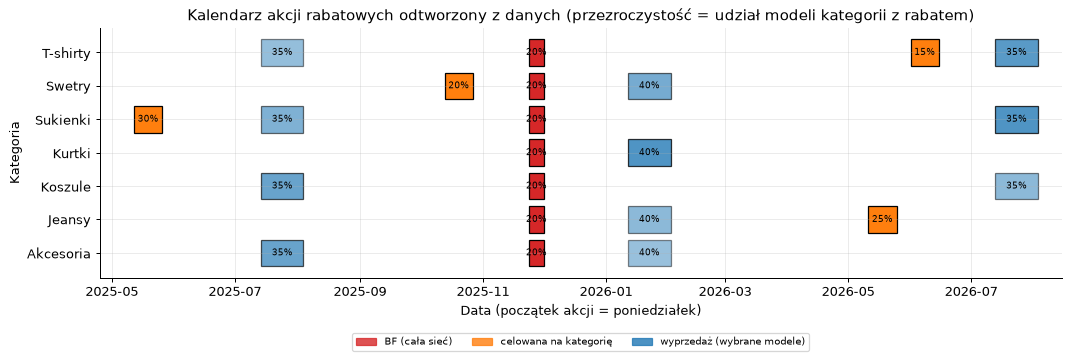

In [21]:
type_color = {"BF (cała sieć)": "#d62728", "celowana na kategorię": "#ff7f0e", "wyprzedaż (wybrane modele)": "#1f77b4"}
cats = list(n_in_cat.index)
fig, ax = plt.subplots(figsize=(12, 4.2))
for _, a in act.iterrows():
    for c in cov[cov.Id == a.Id].itertuples():
        y = cats.index(c.Category)
        ax.barh(y, a.Days, left=mdates.date2num(a.Start), color=type_color[a.Typ], alpha=.35 + .65 * c.z_rabatem / c.w_kategorii, edgecolor="k")
        ax.text(mdates.date2num(a.Start) + a.Days / 2, y, f"{int(a.DiscPct)}%", ha="center", va="center", fontsize=7)
ax.set_yticks(range(len(cats)), cats)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Kalendarz akcji rabatowych odtworzony z danych (przezroczystość = udział modeli kategorii z rabatem)")
ax.set_xlabel("Data (początek akcji = poniedziałek)"); ax.set_ylabel("Kategoria")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, alpha=.8) for c in type_color.values()], labels=list(type_color),
          loc="upper center", bbox_to_anchor=(.5, -.2), ncol=3, fontsize=8)
ax.set_xlim(mdates.date2num(pd.Timestamp("2025-04-25")), mdates.date2num(pd.Timestamp("2026-08-15")))
plt.tight_layout(); plt.show()

**Co widzę.** Kalendarz wygląda na zaplanowany: dwa duże okna wyprzedażowe obejmujące po kilka kategorii (lipiec-sierpień i styczeń), Black Friday na wszystkich, a poza tym akcje na jedną kategorię naraz. Akcje celowane nie nakładają się na siebie, więc dla każdej jest sensowna kontrola z innych kategorii. Kurtki mają rabat tylko w BF i w styczniu 2026 (A5, 4 z 6 modeli): ich elastyczność będzie wynikać z jednej akcji.

### 6.2 Sprzedaż tygodniowa per kategoria i kanał z zaznaczonymi epizodami
**Pytanie:** co wzrasta w tygodniach z rabatem, o ile i jak długo? Rysuję sztuki tygodniowo osobno dla sklepów (suma 5 sklepów) i online. Cieniowanie: tygodnie, w których kategoria miała rabat na przynajmniej jednym modelu (kolor wg typu akcji). Uwaga: seria sklepów w tygodniach świątecznych i po przebudowie Krakowa (od 2026-04-01) ma własną dynamikę; to nie rabat.

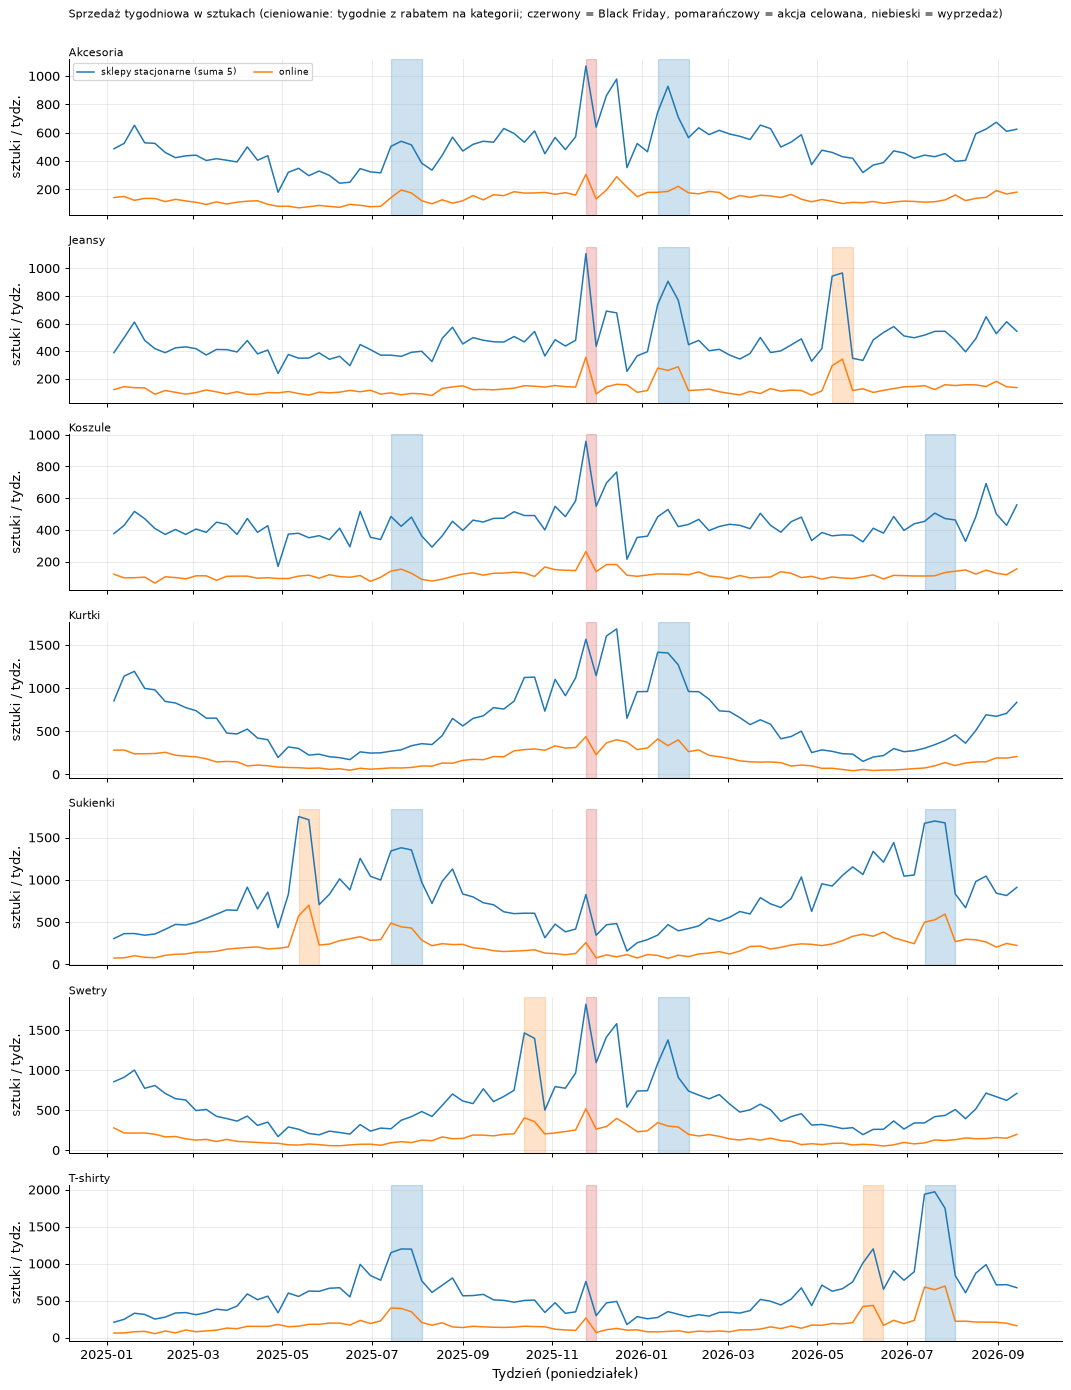

In [22]:
wk_cat_ch = panel.groupby(["Category", "Channel", "WeekStart"]).Qty.sum().unstack("Channel")
fig, axes = plt.subplots(len(cats), 1, figsize=(12, 2.2 * len(cats)), sharex=True)
for ax, c in zip(axes, cats):
    x = wk_cat_ch.loc[c]
    ax.plot(x.index, x["STORE"], label="sklepy stacjonarne (suma 5)", lw=1.2)
    ax.plot(x.index, x["ONLINE"], label="online", lw=1.2)
    for _, a in act.iterrows():
        if (cov[(cov.Id == a.Id)].Category == c).any():
            ax.axvspan(a.Start, a.End + pd.Timedelta(days=1), color=type_color[a.Typ], alpha=.22)
    ax.set_ylabel("sztuki / tydz."); ax.set_title(c, loc="left", fontsize=9, pad=2)
axes[0].legend(loc="upper left", fontsize=7, ncol=2)
axes[-1].set_xlabel("Tydzień (poniedziałek)")
fig.suptitle("Sprzedaż tygodniowa w sztukach (cieniowanie: tygodnie z rabatem na kategorii; czerwony = Black Friday, pomarańczowy = akcja celowana, niebieski = wyprzedaż)", fontsize=9, y=1.0)
plt.tight_layout(); plt.show()

**Co widzę.** (1) W tygodniach akcji sprzedaż kategorii skacze wyraźnie ponad otoczenie, w sklepach i online; skoki są ostre (1-3 tygodnie) i potem sprzedaż wraca w okolice poprzedniego poziomu. (2) **Sezonowość jest silna i różna w kategoriach:** kurtki i swetry rosną jesienią i zimą, sukienki i T-shirty wiosną i latem. Proste „tydzień z rabatem vs reszta roku" jest więc zafałszowane: akcja na sukienki w maju (A1) startuje w narastającym sezonie, a sprzedaż kurtek w styczniu spada po szczycie świątecznym. (3) **Black Friday** (czerwone paski) podnosi sprzedaż we wszystkich kategoriach naraz, więc nie ma kategorii pokazującej „sprzedaż bez rabatu" w tym samym tygodniu. (4) Czy po akcjach jest spadek poniżej poziomu sprzed akcji, z samych wykresów nie rozstrzygnę: sprawdzam to w 6.5 i w Fazie 6.

### 6.3 Kto dostaje rabat? Selekcja do wyprzedaży
**Pytanie (selekcja):** czy modele, które dostały rabat w wyprzedażach końca sezonu (A2, A5, A8: wybrane 8 modeli z 3-4 kategorii), różniły się *wcześniejszą* sprzedażą od modeli tej samej kategorii bez rabatu? Jeśli tak (np. sprzedawały się gorzej), proste porównania „model z rabatem vs bez" mieszają efekt rabatu z cechami modelu. Miara: średnia sprzedaż tygodniowa modelu (wszystkie lokalizacje) w 8 tygodniach **przed** startem akcji, tylko modele bez rabatu w tym oknie. Porównanie z modelami tej samej kategorii, które w akcji rabatu nie dostały (test Manna-Whitneya; to eksploracja, nie test hipotezy, próby są małe).

In [23]:
from scipy import stats
Qm = panel.groupby(["WeekStart", "StyleCode"]).Qty.sum().unstack("StyleCode")      # sztuki tygodniowo, wszystkie lokalizacje razem
rows = []
for _, a in act[act.Typ.str.startswith("wyprzedaż")].iterrows():
    win = [a.Start - pd.Timedelta(weeks=k) for k in range(1, 9)]
    # średnia z tygodni okna, w których sam model nie miał rabatu (A5 poprzedza Black Friday z rabatem na wszystkich modelach)
    pm = {}
    for m in models:
        ok = [w for w in win if DiscW.loc[w, m] == 0]
        if len(ok) >= 4:
            pm[m] = Qm.loc[ok, m].mean()
    pm = pd.Series(pm)
    trm = set(ep[ep.Id == a.Id].StyleCode)
    cats_a = set(cov[cov.Id == a.Id].Category)
    tr = [m for m in pm.index if m in trm]
    co = [m for m in pm.index if m not in trm and cat_of[m] in cats_a]
    oth = [m for m in pm.index if m not in trm and cat_of[m] not in cats_a]
    p = stats.mannwhitneyu(pm[tr], pm[co]).pvalue if len(tr) > 1 and len(co) > 1 else np.nan
    rows.append(dict(Akcja=a.Id, Start=a.Start.date(), rabat_pct=a.DiscPct, n_z_rabatem=len(tr), n_ref_ta_sama_kat=len(co),
                     sztuki_tyg_z_rabatem=pm[tr].mean(), sztuki_tyg_ref=pm[co].mean(), stosunek=pm[tr].mean() / pm[co].mean(), p_MW=p,
                     mediana_z_rabatem=pm[tr].median(), mediana_ref=pm[co].median(), sztuki_tyg_pozostale_kat=pm[oth].mean()))
sel = pd.DataFrame(rows)
print("Sprzedaż tygodniowa modelu w 8 tygodniach PRZED akcją (sztuki/tydzień, wszystkie lokalizacje):")
sel

Sprzedaż tygodniowa modelu w 8 tygodniach PRZED akcją (sztuki/tydzień, wszystkie lokalizacje):


,Akcja,Start,rabat_pct,n_z_rabatem,n_ref_ta_sama_kat,sztuki_tyg_z_rabatem,sztuki_tyg_ref,stosunek,p_MW,mediana_z_rabatem,mediana_ref,sztuki_tyg_pozostale_kat
0,A2,2025-07-14,35.000,8,13,116.882,159.816,0.731,0.301,111.241,157.857,70.908
1,A5,2026-01-12,40.000,8,13,162.107,223.198,0.726,0.121,138.357,182.286,101.324
2,A8,2026-07-13,35.000,8,7,155.307,245.369,0.633,0.336,140.500,184.833,83.571


**Co widzę (selekcja).** We wszystkich trzech wyprzedażach modele, które dostały rabat, sprzedawały się **wcześniej gorzej** niż pozostałe modele tej samej kategorii: stosunek średnich 0,73 (A2), 0,73 (A5), 0,63 (A8); mediany pokazują to samo (np. A8: 141 vs 185 szt./tydz.). Testy Manna-Whitneya pojedynczo nie są istotne (p od 0,12 do 0,34; po 7-13 modeli w grupie), ale kierunek jest ten sam trzy razy z rzędu. Interpretacja (nie fakt): wyprzedaże końca sezonu trafiają na słabiej sprzedające się modele. **Konsekwencja dla metod:** potrzebne są efekty stałe modelu (porównuję model z nim samym w czasie), a porównanie „model z rabatem vs model bez rabatu" zaniżałoby efekt. To podstawa H5.

### 6.4 Co jeszcze dzieje się w tych tygodniach: kategorie bez rabatu obok promowanych
**Pytanie:** czy sprzedaż kategorii bez rabatu też rośnie/spada w tych samych tygodniach (sezon, święta, Black Friday)? Dla każdej akcji rysuję indeks sprzedaży tygodniowej (wszystkie lokalizacje razem, średnia z 4 tygodni przed startem = 100) dla modeli z rabatem i dla **kontroli**: modeli, które nie miały rabatu w oknie od 8 tygodni przed startem do 4 tygodni po końcu akcji. Ten wykres jest opisowy (nie estymuje efektu); do formalnego porównania służy Faza 6. Dla Black Friday (A4) kontroli nie ma: rabat objął wszystkie 36 modeli.

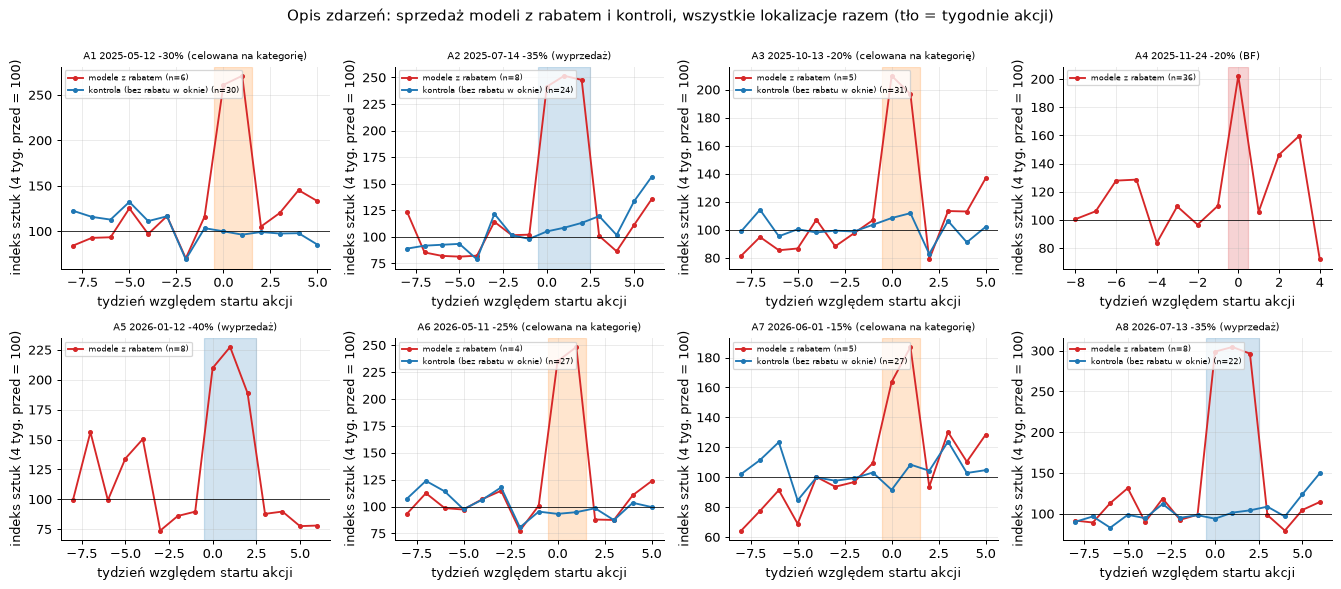

In [24]:
def event_window(a, pre=8, post=4):
    n = int(a.Days // 7)
    rel = np.arange(-pre, n + post)
    wk = [a.Start + pd.Timedelta(weeks=int(k)) for k in rel]
    return n, rel, wk

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=False)
ev_rows = []
for ax, (_, a) in zip(axes.ravel(), act.iterrows()):
    n, rel, wk = event_window(a)
    tr = list(ep[ep.Id == a.Id].StyleCode.unique())
    co = [m for m in models if m not in tr and (DiscW.loc[wk, m] == 0).all()]
    base_w = [a.Start - pd.Timedelta(weeks=k) for k in range(1, 5)]
    for name, group, col in (("modele z rabatem", tr, "C3"), ("kontrola (bez rabatu w oknie)", co, "C0")):
        if len(group) == 0:
            continue
        ser = Qm.loc[wk, group].sum(axis=1)
        base = Qm.loc[base_w, group].sum(axis=1).mean()
        ax.plot(rel, 100 * ser.values / base, marker="o", ms=3, label=f"{name} (n={len(group)})", color=col)
        ev_rows.append(dict(Akcja=a.Id, grupa=name, n_modeli=len(group), **{f"w{r:+d}": 100 * v / base for r, v in zip(rel, ser.values)}))
    ax.axvspan(-.5, n - .5, color=type_color[a.Typ], alpha=.2)
    ax.axhline(100, color="k", lw=.6)
    ax.set_title(f"{a.Id} {a.Start.date()} -{int(a.DiscPct)}% ({a.Typ.split(' (')[0]})", fontsize=8)
    ax.set_xlabel("tydzień względem startu akcji"); ax.set_ylabel("indeks sztuk (4 tyg. przed = 100)")
    ax.legend(fontsize=6, loc="upper left")
fig.suptitle("Opis zdarzeń: sprzedaż modeli z rabatem i kontroli, wszystkie lokalizacje razem (tło = tygodnie akcji)", y=1.0)
plt.tight_layout(); plt.show()

**Co widzę (opis zdarzeń).** (1) Skok w tygodniach akcji jest duży i wyraźnie większy niż w kontroli: modele z rabatem 175-300 w indeksie (4 tyg. przed = 100), kontrola 94-110. (2) W kontrolach widać trendy sezonowe (np. A2: kontrola rośnie od tygodnia +3), a w A1 sukienki rosły już przed akcją, więc **trendy równoległe nie są oczywiste** dla A1 (sukienki) i A7 (T-shirty). To ryzyko dla DiD. (3) Baza „4 tygodnie przed = 100" bywa zaburzona sąsiednią akcją: w A5 w bazie są tygodnie Black Friday i świąt, w A2 koniec A1. (4) Dla A4 (BF) i A5 nie ma kontroli w oknie: BF objął wszystkie modele, a A5 ma BF w oknie ośmiu tygodni przed startem.

### 6.5 Dni po zakończeniu epizodu: czy jest spadek poniżej poziomu sprzed akcji?
**Pytanie:** po akcji, w tygodniach +1 i +2, czy modele z rabatem sprzedają się poniżej poziomu sprzed akcji (znak przesunięcia popytu)? Opisowo: stosunek indeksu modeli z rabatem do indeksu kontroli w tygodniach po akcji (wartość < 1 = poniżej kontroli). To jeszcze nie jest estymacja przyczynowa (kontrola jest wybrana prosto), tylko sygnał do hipotezy H3.

In [25]:
ev = pd.DataFrame(ev_rows)
post_tab = []
for _, a in act.iterrows():
    g = ev[ev.Akcja == a.Id]
    t, c = g[g.grupa == "modele z rabatem"], g[g.grupa.str.startswith("kontrola")]
    n = int(a.Days // 7)
    cols = [f"w{k:+d}" for k in range(n, n + 4)]            # tygodnie po zakończeniu: +1..+4 względem końca
    rec = dict(Akcja=a.Id, Typ=a.Typ.split(" (")[0], rabat_pct=a.DiscPct)
    rec["w_akcji_indeks_rabat"] = t[[f"w{k:+d}" for k in range(0, n)]].mean(axis=1).iloc[0]
    if len(c):
        rec["w_akcji_indeks_kontrola"] = c[[f"w{k:+d}" for k in range(0, n)]].mean(axis=1).iloc[0]
    for i, col in enumerate(cols, 1):
        rec[f"po+{i}_rabat"] = t[col].iloc[0]
        if len(c):
            rec[f"po+{i}_kontrola"] = c[col].iloc[0]
    post_tab.append(rec)
pd.DataFrame(post_tab).round(1)

,Akcja,Typ,rabat_pct,w_akcji_indeks_rabat,w_akcji_indeks_kontrola,po+1_rabat,po+1_kontrola,po+2_rabat,po+2_kontrola,po+3_rabat,po+3_kontrola,po+4_rabat,po+4_kontrola
0,A1,celowana na kategorię,30.000,266.100,98.100,105.200,99.100,120.100,97.500,145.200,97.900,133.200,85.300
1,A2,wyprzedaż,35.000,246.900,108.900,100.900,119.500,86.400,101.700,111.100,133.400,135.300,156.400
2,A3,celowana na kategorię,20.000,203.400,110.200,78.900,82.800,113.400,106.300,113.100,91.100,136.800,102.100
3,A4,BF,20.000,202.300,NaN,105.800,NaN,146.200,NaN,159.800,NaN,72.000,NaN
4,A5,wyprzedaż,40.000,208.700,NaN,87.800,NaN,89.800,NaN,77.600,NaN,78.100,NaN
5,A6,celowana na kategorię,25.000,241.700,94.000,87.900,98.400,87.500,87.400,110.500,103.500,123.600,99.500
6,A7,celowana na kategorię,15.000,175.400,100.000,93.600,104.300,130.200,123.800,110.400,102.800,128.400,104.700
7,A8,wyprzedaż,35.000,300.000,99.900,98.400,108.700,79.400,96.700,104.600,123.800,114.400,149.700


**Co widzę (po akcji).** W większości akcji indeks modeli z rabatem tuż po akcji (tydzień +1) jest niższy niż kontroli: A2 101 vs 120, A6 88 vs 98, A7 94 vs 104, A8 98 vs 109; w tygodniu +2 w A2 (86 vs 102) i A8 (79 vs 97). Wyjątki: A3 (+2: 113 vs 106) i A1 (sukienki w rosnącym sezonie wracają wyżej niż przed akcją). **Jest więc sygnał spadku po akcji rzędu 10-20 pkt indeksu w tygodniach +1/+2, ale niejednoznaczny**: kontrole są niedoskonałe, a akcje różnią się. To za mało na wniosek; H3 sprawdzam estymacją z Fazy 6, gdzie modeluję sezonowość.

### 6.6 Zwroty po zakupach z rabatem i bez
**Pytanie:** czy wskaźnik zwrotów (sztuki zwrócone / sprzedane, przypisane kohortowo do pozycji sprzedaży) zależy od rabatu? Uwzględniam tylko sprzedaż do daty, po której zwroty są praktycznie kompletne (wg opóźnień z sekcji 4.5), osobno dla kanałów. Surowe porównanie miesza kategorie (różne kategorie mają różne zwroty), więc dołączam wersję w obrębie kategorii (pozycje bez rabatu i z rabatem w tej samej kategorii).

In [26]:
sc = s[s.Date <= RET_CUTOFF].copy()
sc["Rabat"] = np.where(sc.DiscountAmount > 0, "z rabatem", "bez rabatu")
t1 = sc.groupby(["Channel", "Rabat"]).agg(sztuki=("Quantity", "sum"), zwroty=("RetQty", "sum"))
t1["wskaznik_zwrotow_%"] = 100 * t1.zwroty / t1.sztuki
print("Wskaźnik zwrotów kohortowo (sztuki), sprzedaż do", RET_CUTOFF.date()); print(t1.round(2))
t2 = sc.groupby(["Channel", "Category", "Rabat"]).apply(lambda g: pd.Series({"sztuki": g.Quantity.sum(), "wsk_%": 100 * g.RetQty.sum() / g.Quantity.sum()}), include_groups=False).unstack("Rabat")
print("\nW obrębie kategorii:"); print(t2.round(1))
t3 = sc[sc.DiscountAmount > 0].groupby(["Channel", "DiscPct"]).apply(lambda g: pd.Series({"sztuki": g.Quantity.sum(), "wsk_%": 100 * g.RetQty.sum() / g.Quantity.sum()}), include_groups=False)
print("\nWedług głębokości rabatu:"); print(t3.round(1).unstack("Channel"))

Wskaźnik zwrotów kohortowo (sztuki), sprzedaż do 2026-08-01
                    sztuki     zwroty  wskaznik_zwrotow_%
Channel Rabat                                            
ONLINE  bez rabatu   78255 14,184.000              18.130
        z rabatem    12779  3,137.000              24.550
STORE   bez rabatu  289640 11,423.000               3.940
        z rabatem    38363  1,746.000               4.550

W obrębie kategorii:
                      sztuki                wsk_%          
Rabat             bez rabatu z rabatem bez rabatu z rabatem
Channel Category                                           
ONLINE  Akcesoria 10,391.000   942.000     18.100    26.200
        Jeansy     9,117.000 1,537.000     18.600    23.400
        Koszule    8,834.000   650.000     17.600    25.200
        Kurtki    13,174.000 1,150.000     18.500    26.100
        Sukienki  14,662.000 3,443.000     17.900    25.100
        Swetry    11,411.000 1,714.000     17.600    23.700
        T-shirty  10,666.000 3


Według głębokości rabatu:
           sztuki             wsk_%      
Channel    ONLINE      STORE ONLINE STORE
DiscPct                                  
15.000    855.000  2,209.000 26.300 4.500
20.000  3,164.000 10,972.000 24.100 4.500
25.000    637.000  1,909.000 22.800 4.600
30.000  1,273.000  3,458.000 26.700 4.700
35.000  4,960.000 13,950.000 23.900 4.600
40.000  1,890.000  5,865.000 25.300 4.500


**Co widzę (zwroty a rabat).** Online wskaźnik zwrotów jest wyraźnie wyższy dla zakupów z rabatem: 24,6% sztuk vs 18,1% bez rabatu (+6,4 pp), **także w obrębie każdej kategorii** (np. Kurtki 26,1% vs 18,5%, Sukienki 25,1% vs 17,9%). W sklepach różnica jest mała: 4,5% vs 3,9% (+0,6 pp; w obrębie kategorii od -0,1 do +1,0 pp). Zaskakujące jest to, że online wskaźnik **nie rośnie z głębokością rabatu** (15%: 26,3%, 20%: 24,1%, 40%: 25,3%): wygląda raczej na „skokową" różnicę dla zakupów z rabatem niż na zależność od głębokości. Mechanizmu z danych nie znam (możliwości: kupowanie „na próbę" w promocji, inny skład klientów; to hipotezy, nie fakty). **Konsekwencja:** akcje online są mniej opłacalne, niż wynika z samej ceny, bo więcej towaru wraca. H6 sprawdzam w Fazie 6 (z efektami stałymi modelu).

### Dziennik pracy: Fazy 2 i 3
- **Zrobiłem:** domknąłem audyt (złączenie zwrotów, opóźnienia zwrotów), zbudowałem panel model x lokalizacja x tydzień, narysowałem kalendarz, sprzedaż tygodniową, selekcję, opis zdarzeń i zwroty.
- **Zobaczyłem:** 8 akcji w 3 typach; ostre skoki sprzedaży o 75-200% w tygodniach akcji; silna sezonowość różna dla kategorii; modele wyprzedażowe sprzedawały się wcześniej gorzej (0,63-0,73 sprzedaży modeli referencyjnych); online zakupy z rabatem wracają o ok. 6 pp częściej.
- **Zaskoczyło:** (1) maksymalny rabat 40%, choć firma opisuje wyprzedaże do 60%; (2) zer prawie nie ma na poziomie model x lokalizacja x tydzień; (3) wskaźnik zwrotów online niezależny od głębokości rabatu; (4) pierwsza wersja porównania selekcji (okno 8 tygodni bez żadnego rabatu) nie działała dla A5, bo okno obejmuje Black Friday: zmieniłem miarę na średnią z tygodni okna, w których dany model nie miał rabatu.
- **Zdecydowałem:** estymacja na poziomie model x kanał x tydzień; Black Friday nie identyfikuje elastyczności (brak kontroli); kontrola sezonowości jest krytyczna.
- **Odrzuciłem:** analizę „wszystkie rabaty razem" (akcje różnią się typem i selekcją); dzienną jednostkę analizy (zbyt rzadka sprzedaż SKU).

## 7. Faza 4: hipotezy i plan identyfikacji (zapisane PRZED budową modeli)

Chronologia pracy: do tego miejsca zrobiłem audyt, odtworzyłem kalendarz i obejrzałem dane opisowo (sekcje 4-6). **Żadnego testu hipotezy ani estymacji efektu jeszcze nie liczyłem.** Poniżej zapisuję hipotezy z oczekiwanym kierunkiem, miarą i progiem decyzji. Dwie z nich (H5, H6) powstały *po* obejrzeniu eksploracji (sekcje 6.3 i 6.6) i mają status **częściowo eksploracyjny**: te same dane, które podsunęły pomysł, posłużą do jego sprawdzenia, więc potwierdzenie jest słabsze niż przy hipotezie sformułowanej bez patrzenia na dane.

### Definicje robocze używane w hipotezach
- **Efekt rabatu (uplift) akcji** = obserwowane sztuki w tygodniach akcji / kontrfakt w tych samych tygodniach - 1, dla modeli objętych akcją. Kontrfakt wylicza dana metoda.
- **Elastyczność** $\varepsilon$: współczynnik przy $\log(1-d)$ w regresji Poissona (patrz Faza 6). Ujemna wartość $d$ rabatu obniża cenę o $d$, więc sprzedaż zmienia się o $(1-d)^{\varepsilon}-1$; przy $\varepsilon<0$ jest to wzrost. Dla czytelności raportuję **$-\varepsilon$** („siła reakcji": o ile % rośnie sprzedaż przy 1% niższej cenie).
- **Okno przesunięcia**: tygodnie +1 i +2 po końcu akcji. **Horyzont zwrotów**: pełny (zwroty kohortowo, ok. 50 dni).
- **Poziom istotności** 0,05; przedziały 95% z bootstrapu klastrowego po modelach (36 klastrów; w obrębie kategorii tylko 4-6 modeli, więc przedziały per kategoria będą szerokie).

### Hipotezy

| ID | Treść | Oczekiwany kierunek | Miara i test | Próg decyzji |
|---|---|---|---|---|
| **H1** | Kategorie różnią się elastycznością (podejrzenie zleceniodawcy: jeansy i T-shirty silniej niż kurtki) | $-\varepsilon$ Jeansy, T-shirty > $-\varepsilon$ Kurtki | współczynniki $\varepsilon_{kat}$ z PPML z przedziałami; łączny test Walda równości 7 współczynników (statystyka z bootstrapu klastrowego) | **Potwierdzona**: p < 0,05 i różnica (średnia Jeansy i T-shirty) - Kurtki ma przedział 95% powyżej 0. **Częściowo**: p < 0,05, ale wzorzec inny niż zakładany. **Odrzucona**: p >= 0,05 |
| **H2** | Naiwne porównanie „okres z rabatem vs bez" zawyża efekt rabatu w akcjach wypadających, gdy bazowa sprzedaż kategorii i tak jest powyżej jej średniej (szczyt sezonowy) | uplift naiwny > uplift z kontrolą | różnica uplift (pp): naiwny (M0) minus z grupą kontrolną i sezonowością (M1/M2), per akcja; zbiorczo bootstrap po modelach | **Potwierdzona**: łączna różnica dla akcji w szczycie >= 10 pp, przedział 95% powyżej 0. **Odrzucona**: przedział zawiera 0 lub różnica < 10 pp |
| **H3** | Po akcji modele z rabatem sprzedają się poniżej kontrfaktu (przesunięcie popytu) | efekt w tygodniach +1 i +2 po akcji < 0 | łączny efekt w oknie „akcja + 2 tyg." vs sam okres akcji; udział przesuniętych sztuk = (ujemne sztuki w +1,+2) / (dodatnie sztuki w akcji); estymata zbiorcza (akcje A1-A3, A5-A8; BF osobno, bo bez kontroli) | **Potwierdzona**: przedział 95% efektu po akcji w całości poniżej 0 i udział przesunięcia >= 10% |
| **H4** | Dla kategorii o niskiej elastyczności wzrost sprzedaży nie pokrywa utraconej marży po zwrotach | uplift netto (po przesunięciu) < próg opłacalności; wpływ na marżę < 0 | wpływ akcji na marżę kohortową w PLN z przedziałem 95%, per kategoria; porównanie uplift z progiem opłacalności z Fazy 1 | **Potwierdzona** dla kategorii, której przedział wpływu na marżę leży poniżej 0 (dla trzech kategorii o najmniejszym $-\varepsilon$). **Niejednoznaczna**: przedział zawiera 0 |
| **H5** | (po eksploracji) Wyprzedaże końca sezonu trafiają na modele, które i tak sprzedają się słabiej, więc regresja bez efektów stałych modelu zaniża efekt rabatu | sprzedaż przed akcją modeli z rabatem < modeli bez rabatu w tej samej kategorii; $-\varepsilon$ bez efektu stałego modelu < z efektem stałym | (a) stosunek sprzedaży w 8 tyg. przed akcją (A2, A5, A8 łącznie, z efektem stałym kategorii); (b) $-\varepsilon$ w PPML z i bez efektów stałych modelu | **Potwierdzona**: (a) stosunek < 0,9 z przedziałem 95% poniżej 1 **oraz** (b) $-\varepsilon$ bez FE mniejsze o co najmniej 20% niż z FE |
| **H6** | (po eksploracji, eksploracyjna) Zakup z rabatem częściej wraca, tylko online | wskaźnik zwrotów online z rabatem > bez rabatu o >= 3 pp (w sklepach < 1 pp) | różnica wskaźnika zwrotów (sztuki, kohortowo) w obrębie modelu: regresja z efektami stałymi modelu x kanał | **Potwierdzona**: online >= 3 pp z przedziałem 95% powyżej 0; sklepy |różnica| < 1 pp |

Rodzina testów konfirmacyjnych: H1-H5 (5 hipotez, korekta Holma przy zbiorczym podsumowaniu). H6 jest eksploracyjna. Wszystkie wykonane testy trafiają do rejestru testów (tabela w sekcji 10).

### Plan identyfikacji: grupy kontrolne i testy założeń

Dane są obserwacyjne, a rabat jest identyczny we wszystkich lokalizacjach. Identyfikuję efekt wyłącznie z różnic **między modelami** i **w czasie**. Każda akcja ma inną naturę, więc inną kontrolę:

| Akcja | Kto dostał rabat | Grupa kontrolna | Główne ryzyko |
|---|---|---|---|
| A1, A3, A6, A7 (celowane na kategorię) | cała kategoria | modele pozostałych kategorii bez rabatu w oknie | inna sezonowość kategorii (np. rosnący sezon sukienek na wiosnę): trend równoległy może nie zachodzić |
| A2, A5, A8 (wyprzedaże końca sezonu) | wybrane modele z 3-4 kategorii | niepromowane modele z tych samych kategorii (ta sama sezonowość) i pozostałe kategorie | selekcja modeli (kto je wybrał?) |
| A4 (Black Friday) | wszystkie 36 modeli | brak kontroli w tym samym tygodniu | efekt rabatu jest nieodróżnialny od efektu samego Black Friday. Nie estymuję go bezpośrednio: pokazuję, ile z wzrostu wyjaśnia elastyczność z innych akcji, a resztę opisuję jako niezidentyfikowaną |

**Testy założeń.** (1) *Trendy równoległe:* w event study (tygodnie -8..-1 przed akcją) łączny test Walda, że współczynniki wyprzedzeń wynoszą 0 (poziom ostrzegawczy 0,10, bo test ma małą moc, i jednocześnie oglądam wykres). (2) *Sezonowość kategorii:* w regresji Poissona dodaję składowe sezonowe (harmoniczne tygodnia roku) osobno dla każdej kategorii oraz efekty stałe kanał x tydzień; BF traktuję osobnymi wskaźnikami kategorii (nie identyfikuje elastyczności). (3) *Przesunięcie popytu:* wskaźniki tygodni +1, +2 (oraz +3, +4 opisowo) po akcji dla modeli z rabatem. (4) *Odporność:* placebo, zmiana kontroli i okien, wyłączanie akcji pojedynczo (Faza 7).

**Zakres wniosków.** Obserwowane głębokości: 15, 20, 25, 30, 35, 40%; wniosków o głębszych rabatach nie wolno wyciągać.

**Plan walidacji metod** (jedna walidacja dla M0-M3): kolejne wyłączanie jednej akcji (leave-one-action-out): estymacja na pozostałych akcjach, predykcja upliftu wyłączonej akcji, porównanie z obserwowanym. Metryka: błąd bezwzględny upliftu w pp.

In [27]:
# Rejestr wszystkich wykonanych testów (także tych nieudanych), żeby nie ukryć wielokrotnych porównań.
TESTS = []

def register(hyp, name, estimate, ci_or_p, decision=""):
    TESTS.append(dict(hipoteza=hyp, test=name, wynik=estimate, przedzial_lub_p=ci_or_p, decyzja=decision))

print("rejestr testów utworzony; testów dotychczas:", len(TESTS), "(w sekcjach 4-6 nie wykonywałem testów hipotez; test Manna-Whitneya w 6.3 jest opisowy)")

rejestr testów utworzony; testów dotychczas: 0 (w sekcjach 4-6 nie wykonywałem testów hipotez; test Manna-Whitneya w 6.3 jest opisowy)


## 8. Analyze

### 8.1 Faza 5: naiwny punkt odniesienia (M0)

**Po co.** Zleceniodawca zaczyna od porównania „tygodnie z rabatem vs reszta". Odtwarzam je, żeby zobaczyć skalę błędu, nie jako wynik. Dla każdej akcji: sztuki tygodniowe modeli objętych akcją w tygodniach akcji, porównane ze **sztukami tych samych modeli w WSZYSTKICH pozostałych tygodniach bez rabatu** całego okresu danych (to „reszta roku" z pytania zleceniodawcy). Uplift naiwny = średnia(akcja) / średnia(reszta) - 1. Jednostka: model x tydzień (osobno sklepy, online). Przedział 95%: bootstrap po modelach (modele to klastry: tygodnie jednego modelu nie są niezależne). Testy: Welcha (różnica średnich, nierówne wariancje) i Manna-Whitneya (bez założenia normalności); poziom 0,05; założenie niezależności obserwacji jest tu **naruszone** (to jedna z przyczyn, dla których M0 nie jest wynikiem).

**Próg opłacalności** (wzór z Fazy 1), dla każdej akcji i kanału z danymi:
$$\text{wymagany uplift}=\frac{m_0}{m_1}-1,$$
gdzie $m_0, m_1$ to marża jednostkowa netto bez rabatu i z rabatem (z udziałem kosztu $k$ i wskaźnikami zwrotów $\rho_0,\rho_1$ zmierzonymi w danych dla tych modeli i kanału: bez rabatu vs w akcji). Wariant **A** (słownikowy: zwrócony towar odpisany, koszt zostaje) i **B** (zwrócony towar wraca do sprzedaży po koszcie).

In [28]:
Pm = (panel.groupby(["StyleCode", "Channel", "WeekStart"], as_index=False)
      .agg(Qty=("Qty", "sum"), ValuePre=("ValuePre", "sum"), DiscAmt=("DiscAmt", "sum"), Net=("Net", "sum"), COGS=("COGS", "sum"),
           RetQty=("RetQty", "sum"), RetGross=("RetGross", "sum"), RetCOGS=("RetCOGS", "sum")))
Pm = Pm.merge(dw, on=["WeekStart", "StyleCode"], how="left")
Pm["Category"] = Pm.StyleCode.map(cat_of)
Pm["t"] = ((Pm.WeekStart - weeks[0]).dt.days // 7).astype(int)             # numer tygodnia 0..88
Pm["woy"] = Pm.WeekStart.dt.isocalendar().week.astype(int).values
print("Pm (model x kanał x tydzień):", Pm.shape, "| modeli:", Pm.StyleCode.nunique(), "| tygodni:", Pm.t.nunique())

# całkowite sztuki modelu w tygodniu (oba kanały razem) jako trzeci "widok"
Pall = Pm.groupby(["StyleCode", "WeekStart"], as_index=False).agg(Qty=("Qty", "sum"))
Pall = Pall.merge(dw, on=["WeekStart", "StyleCode"]); Pall["Channel"] = "RAZEM"
views = {"STORE": Pm[Pm.Channel == "STORE"], "ONLINE": Pm[Pm.Channel == "ONLINE"], "RAZEM": Pall}

def action_weeks(a):
    return [a.Start + pd.Timedelta(weeks=k) for k in range(int(a.Days // 7))]

def naive_stats(a, df, B=2000, seed=0):
    """Uplift naiwny akcji a na ramce df (kolumny StyleCode, WeekStart, Qty, d)."""
    tr = list(ep[ep.Id == a.Id].StyleCode.unique())
    aw = action_weeks(a)
    d_tr = df[df.StyleCode.isin(tr)]
    act_rows = d_tr[d_tr.WeekStart.isin(aw)]
    ref_rows = d_tr[d_tr.d == 0]                                        # wszystkie tygodnie tych modeli bez rabatu
    g_a = act_rows.groupby("StyleCode").Qty.agg(["sum", "count"]).reindex(tr)
    g_r = ref_rows.groupby("StyleCode").Qty.agg(["sum", "count"]).reindex(tr)
    est = (g_a["sum"].sum() / g_a["count"].sum()) / (g_r["sum"].sum() / g_r["count"].sum()) - 1
    r = np.random.default_rng(seed)
    bs = np.empty(B)
    for b in range(B):
        ix = r.integers(0, len(tr), len(tr))
        bs[b] = (g_a["sum"].values[ix].sum() / g_a["count"].values[ix].sum()) / (g_r["sum"].values[ix].sum() / g_r["count"].values[ix].sum()) - 1
    w_p = stats.ttest_ind(act_rows.Qty, ref_rows.Qty, equal_var=False).pvalue
    mw_p = stats.mannwhitneyu(act_rows.Qty, ref_rows.Qty).pvalue
    return est, np.percentile(bs, 2.5), np.percentile(bs, 97.5), w_p, mw_p, len(act_rows), len(ref_rows)

m0_rows = []
for _, a in act.iterrows():
    for ch, df in views.items():
        est, lo, hi, w_p, mw_p, n1, n0 = naive_stats(a, df)
        m0_rows.append(dict(Akcja=a.Id, Typ=a.Typ.split(" (")[0], rabat=a.DiscPct / 100, kanal=ch, uplift_naiwny=est, ci_lo=lo, ci_hi=hi,
                            p_Welch=w_p, p_MW=mw_p, n_akcja=n1, n_ref=n0))
M0 = pd.DataFrame(m0_rows)
for r_ in M0.itertuples():
    register("M0 (baseline)", f"{r_.Akcja} {r_.kanal}: akcja vs reszta (Welch / MW)", f"uplift {r_.uplift_naiwny:+.0%}", f"p_W={r_.p_Welch:.1e}, p_MW={r_.p_MW:.1e}", "baseline, nie wynik")
print("Uplift naiwny (sztuki w tygodniach akcji / sztuki tych modeli w tygodniach bez rabatu - 1):")
M0.pivot(index="Akcja", columns="kanal", values="uplift_naiwny").join(M0[M0.kanal == "RAZEM"].set_index("Akcja")[["Typ", "rabat", "ci_lo", "ci_hi", "p_Welch", "p_MW"]]).round(3)

Pm (model x kanał x tydzień): (6408, 15) | modeli: 36 | tygodni: 89


Uplift naiwny (sztuki w tygodniach akcji / sztuki tych modeli w tygodniach bez rabatu - 1):


,ONLINE,RAZEM,STORE,Typ,rabat,ci_lo,ci_hi,p_Welch,p_MW
Akcja,,,,,,,,,
A1,2.220,1.576,1.399,celowana na kategorię,0.300,1.386,1.861,0.001,0.000
A2,2.060,1.465,1.302,wyprzedaż,0.350,0.563,2.531,0.000,0.000
A3,1.617,1.647,1.655,celowana na kategorię,0.200,1.389,1.987,0.000,0.000
A4,1.368,1.207,1.163,BF,0.200,0.913,1.532,0.000,0.000
A5,2.956,2.433,2.293,wyprzedaż,0.400,1.807,3.254,0.000,0.000
A6,1.683,1.268,1.156,celowana na kategorię,0.250,1.060,1.545,0.000,0.000
A7,1.962,1.264,1.075,celowana na kategorię,0.150,1.172,1.369,0.000,0.000
A8,4.122,3.054,2.764,wyprzedaż,0.350,2.056,4.037,0.000,0.000


In [29]:
# Próg opłacalności w każdej akcji i kanale: udział kosztu k, zwroty bez rabatu (rho0) i w akcji (rho1) zmierzone dla modeli akcji.
cut_t = (RET_CUTOFF - pd.Timedelta(days=6) - weeks[0]).days // 7        # tylko tygodnie z (prawie) kompletnymi zwrotami

def required_uplift(d, k, rho0, rho1, variant):
    p = 1.0
    if variant == "A":                       # zwrot odpisany: koszt zostaje, przychód wraca klientowi
        m0, m1 = p * (1 - rho0) - k, p * (1 - d) * (1 - rho1) - k
    elif variant == "B":                     # zwrot wraca na stan po koszcie
        m0, m1 = (p - k) * (1 - rho0), (p * (1 - d) - k) * (1 - rho1)
    else:                                    # bez zwrotów (wzór z Fazy 1)
        m0, m1 = p - k, p * (1 - d) - k
    return m0 / m1 - 1 if m1 > 0 else np.inf

th_rows = []
for _, a in act.iterrows():
    tr = list(ep[ep.Id == a.Id].StyleCode.unique()); aw = action_weeks(a); d = a.DiscPct / 100
    for ch in ("STORE", "ONLINE"):
        x = Pm[(Pm.Channel == ch) & Pm.StyleCode.isin(tr)]
        xa, xr = x[x.WeekStart.isin(aw)], x[(x.d == 0) & (x.t <= cut_t)]
        k = xa.COGS.sum() / (xa.ValuePre.sum() / 1.23)                  # koszt / cena katalogowa netto, mix z akcji
        rho0 = xr.RetQty.sum() / xr.Qty.sum()
        xa_c = xa[xa.t <= cut_t]
        rho1 = xa_c.RetQty.sum() / xa_c.Qty.sum() if len(xa_c) else np.nan
        th_rows.append(dict(Akcja=a.Id, kanal=ch, rabat=d, k_koszt_do_ceny=k, rho0_bez_rabatu=rho0, rho1_w_akcji=rho1,
                            prog_bez_zwrotow=required_uplift(d, k, 0, 0, "-"), prog_A=required_uplift(d, k, rho0, rho1, "A"),
                            prog_B=required_uplift(d, k, rho0, rho1, "B")))
TH = pd.DataFrame(th_rows)
TH.round(3)

,Akcja,kanal,rabat,k_koszt_do_ceny,rho0_bez_rabatu,rho1_w_akcji,prog_bez_zwrotow,prog_A,prog_B
0,A1,STORE,0.300,0.357,0.040,0.047,0.875,0.944,0.888
1,A1,ONLINE,0.300,0.359,0.179,0.267,0.879,1.996,1.105
2,A2,STORE,0.350,0.344,0.039,0.041,1.143,1.208,1.148
3,A2,ONLINE,0.350,0.343,0.177,0.255,1.140,2.397,1.363
4,A3,STORE,0.200,0.379,0.039,0.051,0.475,0.531,0.493
5,A3,ONLINE,0.200,0.382,0.176,0.252,0.479,1.048,0.630
6,A4,STORE,0.200,0.367,0.039,0.043,0.462,0.488,0.467
7,A4,ONLINE,0.200,0.365,0.181,0.238,0.460,0.855,0.568
8,A5,STORE,0.400,0.377,0.038,0.045,1.795,1.980,1.813
9,A5,ONLINE,0.400,0.374,0.184,0.253,1.767,4.927,2.022


In [30]:
# Naiwny wniosek o opłacalności: uplift naiwny (dolna granica przedziału) vs próg A. Pokazuje, jak łatwo „wyjdzie, że się opłaca".
cmp0 = M0[M0.kanal.isin(["STORE", "ONLINE"])].merge(TH, left_on=["Akcja", "kanal"], right_on=["Akcja", "kanal"])
cmp0["naiwny_wniosek"] = np.where(cmp0.ci_lo >= cmp0.prog_A, "opłaca się", np.where(cmp0.ci_hi < cmp0.prog_A, "nie opłaca się", "niejednoznaczny"))
cmp0[["Akcja", "kanal", "rabat_x", "uplift_naiwny", "ci_lo", "ci_hi", "prog_A", "prog_B", "naiwny_wniosek"]].round(3)

,Akcja,kanal,rabat_x,uplift_naiwny,ci_lo,ci_hi,prog_A,prog_B,naiwny_wniosek
0,A1,STORE,0.300,1.399,1.223,1.665,0.944,0.888,opłaca się
1,A1,ONLINE,0.300,2.220,1.759,2.891,1.996,1.105,niejednoznaczny
2,A2,STORE,0.350,1.302,0.491,2.258,1.208,1.148,niejednoznaczny
3,A2,ONLINE,0.350,2.060,0.826,3.513,2.397,1.363,niejednoznaczny
4,A3,STORE,0.200,1.655,1.378,1.997,0.531,0.493,opłaca się
5,A3,ONLINE,0.200,1.617,1.421,1.990,1.048,0.630,opłaca się
6,A4,STORE,0.200,1.163,0.878,1.482,0.488,0.467,opłaca się
7,A4,ONLINE,0.200,1.368,1.050,1.734,0.855,0.568,opłaca się
8,A5,STORE,0.400,2.293,1.763,2.944,1.980,1.813,niejednoznaczny
9,A5,ONLINE,0.400,2.956,1.965,4.446,4.927,2.022,nie opłaca się


### 8.1b Typy akcji razem (test Welcha i Manna-Whitneya)

**Po co.** Zleceniodawca pyta zbiorczo („jak działa rabat sezonowy, jak Black Friday"). Łączę akcje tego samego typu i porównuję model-tygodnie akcji z model-tygodniami bez rabatu tych samych modeli (każdy tydzień jako osobna obserwacja; założenie niezależności jest naruszone, więc p-wartości są **zbyt optymistyczne**; służą pokazaniu skali, nie wnioskowaniu).

In [31]:
trows = []
for typ in act.Typ.unique():
    ids = act[act.Typ == typ].Id.tolist()
    for ch, df in views.items():
        a_idx, r_idx = [], []
        for _, a in act[act.Id.isin(ids)].iterrows():
            tr = list(ep[ep.Id == a.Id].StyleCode.unique())
            a_idx.append(df[df.StyleCode.isin(tr) & df.WeekStart.isin(action_weeks(a))].Qty)
        trs = set(ep[ep.Id.isin(ids)].StyleCode)
        r_idx = df[df.StyleCode.isin(trs) & (df.d == 0)].Qty
        qa = pd.concat(a_idx)
        wp, mp = stats.ttest_ind(qa, r_idx, equal_var=False).pvalue, stats.mannwhitneyu(qa, r_idx).pvalue
        trows.append(dict(typ=typ, kanal=ch, n_akcja=len(qa), n_ref=len(r_idx), sr_akcja=qa.mean(), sr_ref=r_idx.mean(), uplift=qa.mean() / r_idx.mean() - 1, p_Welch=wp, p_MW=mp))
        register("M0 (baseline)", f"typ '{typ}' {ch}: Welch / MW", f"uplift {qa.mean() / r_idx.mean() - 1:+.0%}", f"p_W={wp:.1e}, p_MW={mp:.1e}", "baseline, nie wynik")
pd.DataFrame(trows).round(3)

,typ,kanal,n_akcja,n_ref,sr_akcja,sr_ref,uplift,p_Welch,p_MW
0,celowana na kategorię,STORE,40,1681,260.925,111.686,1.336,0.000,0.000
1,celowana na kategorię,ONLINE,40,1681,88.150,30.295,1.910,0.000,0.000
2,celowana na kategorię,RAZEM,40,1681,349.075,141.982,1.459,0.000,0.000
3,wyprzedaż (wybrane modele),STORE,72,1756,275.208,87.084,2.160,0.000,0.000
4,wyprzedaż (wybrane modele),ONLINE,72,1756,97.417,23.550,3.137,0.000,0.000
5,wyprzedaż (wybrane modele),RAZEM,72,1756,372.625,110.634,2.368,0.000,0.000
6,BF (cała sieć),STORE,36,3056,225.306,104.151,1.163,0.000,0.000
7,BF (cała sieć),ONLINE,36,3056,66.750,28.189,1.368,0.000,0.000
8,BF (cała sieć),RAZEM,36,3056,292.056,132.340,1.207,0.000,0.000


## 8.2 Faza 6, metoda M1: regresja Poissona (PPML) z efektami stałymi

**Po co.** M0 porównuje tygodnie z rabatem z „resztą", więc miesza rabat z sezonem i z cechami modeli. M1 ma to rozdzielić: porównuje **ten sam model z samym sobą w czasie** (efekt stały modelu), w **tym samym tygodniu** co inne modele (efekt stały tygodnia), a rabat opisuje zmienną $\log(1-d)$, gdzie $d$ to stopa rabatu. Współczynnik przy tej zmiennej to **elastyczność cenowa** $\varepsilon$ (o ile % zmieniają się sztuki, gdy cena spada o 1%). Raportuję $-\varepsilon$ („siła reakcji": dodatnia liczba = rabat zwiększa sprzedaż).

**Specyfikacja** (jednostka: model x kanał x tydzień; sklepy stacjonarne zsumowane, bo rabat jest identyczny we wszystkich sklepach):

$$E[\text{sztuki}_{m,c,t}] = \exp\Big(\alpha_{m,c} + \lambda_{c,t} + \text{sezon}_{\text{kat}(m)}(t) + \text{BF}_{\text{kat}(m),c}\cdot 1[t=\text{BF}] + \varepsilon_{\text{kat}(m),c}\cdot\log(1-d_{m,t}) + \gamma_{c,1}\,\text{po}_1 + \gamma_{c,2}\,\text{po}_2\Big)$$

- $\alpha_{m,c}$: efekt stały modelu w kanale (wyłapuje, że jedne modele sprzedają się lepiej, w tym **selekcję** słabych modeli do wyprzedaży);
- $\lambda_{c,t}$: efekt stały kanału i tygodnia (święta, przebudowa Krakowa, wszystko, co dotyczy wszystkich modeli naraz);
- sezon: dwie harmoniczne tygodnia roku **osobno dla każdej kategorii** (kurtki i sukienki mają inną sezonowość; sam efekt tygodnia tego nie złapie);
- BF: **Black Friday ma osobne wskaźniki kategorii**. Rabat 20% objął wtedy wszystkie modele, więc BF nie da się odróżnić od samego „tygodnia Black Friday"; wyłączam go z identyfikacji elastyczności (zamiast tego sprawdzę później, co by wynikało z elastyczności z innych akcji);
- $\text{po}_1,\text{po}_2$: wskaźniki 1. i 2. tygodnia po zakończeniu akcji dla modeli z akcji (osobno kanały). Bez nich dołek po akcji (przesunięcie popytu) zostałby wchłonięty do „zwykłej" sprzedaży i zawyżałby elastyczność. $\gamma<0$ oznacza dołek (H3);
- $\varepsilon_{\text{kat},c}$: osobna elastyczność dla każdej kategorii i kanału (14 współczynników). Dla H1 dodatkowo specyfikacja z jedną elastycznością na kategorię i przesunięciem dla online.

**Założenia identyfikujące** (do przetestowania w Fazie 7): (a) po uwzględnieniu efektów stałych i sezonowości kategorii **bez rabatu** modele z rabatem rozwijałyby się jak pozostałe (analog trendów równoległych); (b) rabat nie jest nadawany w odpowiedzi na chwilowy skok sprzedaży konkretnego modelu; (c) elastyczność jest stała w obserwowanym zakresie głębokości (15-40%), co jest uproszczeniem; (d) brak innych zdarzeń specyficznych dla modeli z rabatem (np. kampanii reklamowej tylko na te modele; firma nie ma takich danych).

**Wnioskowanie.** Błędy standardowe i przedziały: **bootstrap klastrowy po modelach**, losowanie ze zwracaniem *w obrębie kategorii* (w kategorii jest tylko 4-6 modeli; losowanie ogólne mogłoby wylosować kategorię bez modeli z rabatem). Model = klaster, bo jego kolejne tygodnie nie są niezależne. Losowań: 300 (specyfikacje główne), przedziały percentylowe 95%. Wyniki w cache (`cache/boot_*.npz`), więc kolejne uruchomienie nie liczy ich od nowa.

In [32]:
import importlib, time
sys.path.insert(0, str(CACHE.parent / "src"))
import ppml as PP
importlib.reload(PP)
from scipy.stats import chi2

bf_start = act.loc[act.Typ.str.startswith("BF"), "Start"].iloc[0]

# komórki "tydzień po akcji" dla modeli z akcji (poza BF: po BF nie da się wydzielić dołka, bo wszystkie modele miały rabat naraz)
pc_rows = []
for _, a in act[~act.Typ.str.startswith("BF")].iterrows():
    for k in (1, 2):
        wk = a.End + pd.Timedelta(days=1) + pd.Timedelta(weeks=k - 1)
        for m in ep[ep.Id == a.Id].StyleCode.unique():
            pc_rows.append((m, wk, k, a.Id))
post_cells = pd.DataFrame(pc_rows, columns=["StyleCode", "WeekStart", "k", "Id"]).merge(
    dw.rename(columns={"d": "d_w"}), on=["StyleCode", "WeekStart"], how="left")
print("komórek 'po akcji' (model x tydzień):", len(post_cells), "| z rabatem w tym tygodniu (kolizja z inną akcją):", int((post_cells.d_w > 0).sum()))
post_cells = post_cells[(post_cells.d_w == 0) & (post_cells.WeekStart != bf_start)]

D_cc = PP.Design(Pm, bf_start, post_cells, spec="cc")
D_cat = PP.Design(Pm, bf_start, post_cells, spec="cat")
D_pool = PP.Design(Pm, bf_start, post_cells, spec="pooled")
print("macierz projektu (bez efektów modelu):", D_cc.B.shape, "| wierszy panelu:", len(D_cc.y))

t0 = time.time()
f_cc = D_cc.fit(cov=True)
print(f"jedno dopasowanie PPML: {time.time() - t0:.2f} s | korelacja obserwowane vs dopasowane: {np.corrcoef(f_cc['y'], f_cc['mu'])[0, 1]:.3f}")

komórek 'po akcji' (model x tydzień): 88 | z rabatem w tym tygodniu (kolizja z inną akcją): 0
macierz projektu (bez efektów modelu): (6408, 238) | wierszy panelu: 6408


jedno dopasowanie PPML: 0.44 s | korelacja obserwowane vs dopasowane: 0.970


In [33]:
# Losowania bootstrapu klastrowego (stratyfikowanego po kategorii); współczynniki leczenia i tygodni po akcji z każdego losowania.
def boot(D, name, B, fe="model", seed=1, extra=None):
    path = CACHE / f"boot_{name}.npz"
    if path.exists():
        z = np.load(path)
        return z["coefs"], (z["extra"] if "extra" in z else None)
    r = np.random.default_rng(seed)
    cols = D.ti + D.pi
    out = np.full((B, len(cols)), np.nan)
    ext = [] if extra is not None else None
    for i in range(B):
        idx = D.strat_draw(r)
        rows, X = D.matrix(idx, fe)
        y = D.y[rows]
        b, mu, _ = PP.ppml(X, y)
        ok = (np.abs(X[:, cols]).sum(axis=0) > 0)                # współczynnik nieidentyfikowalny, gdy w próbie nie ma żadnej obserwacji leczonej
        out[i] = np.where(ok, b[cols], np.nan)
        if extra is not None:
            ext.append(extra(idx))
    ext = np.array(ext) if extra is not None else None
    np.savez(path, coefs=out, **({"extra": ext} if ext is not None else {}))
    return out, ext

# dla H2: statystyki M0 (naiwny uplift) liczone na TYCH SAMYCH losowaniach modeli, więc różnica M0-M1 jest sparowana
act_ns = act[~act.Typ.str.startswith("BF")].reset_index(drop=True)
Pall_q = Pm.groupby(["StyleCode", "WeekStart"], as_index=False).Qty.sum().merge(dw, on=["StyleCode", "WeekStart"])
M0_arr = np.zeros((len(act_ns), 4, len(D_cc.models)))             # [akcja, (suma w akcji, liczba model-tygodni w akcji, suma w reszcie, liczba w reszcie), model]
mi = {m: i for i, m in enumerate(D_cc.models)}
for ai, a in act_ns.iterrows():
    aw = action_weeks(a)
    for m in ep[ep.Id == a.Id].StyleCode.unique():
        g = Pall_q[Pall_q.StyleCode == m]
        ga, gr = g[g.WeekStart.isin(aw)], g[g.d == 0]
        M0_arr[ai, :, mi[m]] = [ga.Qty.sum(), len(ga), gr.Qty.sum(), len(gr)]

def m0_extra(idx):
    mult = np.bincount(idx, minlength=len(D_cc.models))
    return (M0_arr * mult[None, None, :]).sum(axis=2)             # (akcja, 4)

t0 = time.time()
BOOT_B = 300
coef_cc, m0_draws = boot(D_cc, "cc", BOOT_B, seed=11, extra=m0_extra)
coef_cat, _ = boot(D_cat, "cat", BOOT_B, seed=12)
print(f"bootstrap (cache lub nowe obliczenie): {time.time() - t0:.0f} s | losowań: {len(coef_cc)} | losowań z brakującym współczynnikiem (cc): {int(np.isnan(coef_cc).any(axis=1).sum())}")

bootstrap (cache lub nowe obliczenie): 0 s | losowań: 300 | losowań z brakującym współczynnikiem (cc): 4


In [34]:
# Tabela elastyczności: kategoria x kanał. Pokazuję -eps (siła reakcji) z przedziałem bootstrapowym i SE klastrowym (porównanie).
names_t = D_cc.treat_names
b_cc = f_cc["b"][D_cc.ti]
se_cc = np.sqrt(np.diag(f_cc["V"]))[D_cc.ti]
rows_el = []
for j, n in enumerate(names_t):
    _, cat_, chn_ = n.split("_", 2)
    q = np.nanpercentile(-coef_cc[:, j], [2.5, 97.5])
    rows_el.append(dict(kategoria=cat_, kanal=chn_, minus_eps=-b_cc[j], boot_lo=q[0], boot_hi=q[1], SE_klastrowe=se_cc[j],
                        sklastr_lo=-b_cc[j] - 1.96 * se_cc[j], sklastr_hi=-b_cc[j] + 1.96 * se_cc[j]))
EL = pd.DataFrame(rows_el)
print("Elastyczność (-eps) z M1 PPML: sztuki +x% przy cenie -1%. Przedziały 95%: bootstrap klastrowy (kolumny boot_*) i asymptotyczne z SE klastrowych.")
EL.pivot(index="kategoria", columns="kanal", values=["minus_eps", "boot_lo", "boot_hi"]).round(2)

Elastyczność (-eps) z M1 PPML: sztuki +x% przy cenie -1%. Przedziały 95%: bootstrap klastrowy (kolumny boot_*) i asymptotyczne z SE klastrowych.


minus_eps       boot_lo       boot_hi      
kanal        ONLINE STORE  ONLINE STORE  ONLINE STORE
kategoria                                            
Akcesoria     2.150 1.710   1.210 0.810   2.580 2.080
Jeansy        3.920 2.900   3.430 2.520   4.150 3.120
Koszule       1.640 1.190   1.370 0.960   2.010 1.620
Kurtki        0.870 0.670   0.640 0.410   1.100 0.880
Sukienki      2.500 1.800   2.250 1.690   2.740 1.960
Swetry        1.730 1.440   1.560 1.150   1.930 1.900
T-shirty      3.560 2.620   3.440 2.380   3.710 2.710

In [35]:
# Tygodnie po akcji (przesunięcie popytu): współczynniki gamma (skala log) i procentowa zmiana sprzedaży modeli z akcji w tygodniu +1/+2.
npost = len(D_cc.pi)
rows_po = []
for j, n in enumerate(D_cc.post_names):
    g = f_cc["b"][D_cc.pi[j]]
    q = np.nanpercentile(coef_cc[:, len(D_cc.ti) + j], [2.5, 97.5])
    rows_po.append(dict(wskaznik=n, wsp_log=g, zmiana_pct=np.exp(g) - 1, lo_pct=np.exp(q[0]) - 1, hi_pct=np.exp(q[1]) - 1))
PO = pd.DataFrame(rows_po)
print("Sprzedaż modeli z akcji w tygodniu +1 / +2 po jej końcu względem kontrfaktu (M1; 95% bootstrap):")
PO.round(3)

Sprzedaż modeli z akcji w tygodniu +1 / +2 po jej końcu względem kontrfaktu (M1; 95% bootstrap):


,wskaznik,wsp_log,zmiana_pct,lo_pct,hi_pct
0,post1_ONLINE,-0.110,-0.104,-0.176,-0.019
1,post1_STORE,-0.174,-0.160,-0.206,-0.112
2,post2_ONLINE,-0.048,-0.047,-0.104,0.017
3,post2_STORE,-0.112,-0.106,-0.157,-0.055


### Test H1 (różnice elastyczności między kategoriami)

**Zapisane wcześniej (sekcja 7):** potwierdzona, jeśli łączny test Walda równości 7 elastyczności ma p < 0,05 **i** (średnia $-\varepsilon$ Jeansy i T-shirty) minus $-\varepsilon$ Kurtki ma przedział 95% powyżej 0. Używam specyfikacji z jedną elastycznością na kategorię (kanały mają wspólny współczynnik + przesunięcie dla online), statystyka Walda z macierzą kowariancji z bootstrapu klastrowego, rozkład $\chi^2_6$. Poziom istotności 0,05; metoda i założenia: asymptotyka Walda przy 36 klastrach jest przybliżeniem, dlatego podaję też wersję z SE klastrowymi z jednego dopasowania.

In [36]:
f_cat = D_cat.fit(cov=True)
ncat = len(D_cat.cats)
R = np.zeros((ncat - 1, ncat + 1))
R[:, 0] = 1; R[np.arange(ncat - 1), np.arange(1, ncat)] = -1         # eps_1 - eps_k = 0, k = 2..7
b_c = f_cat["b"][D_cat.ti]
ok = ~np.isnan(coef_cat[:, :ncat + 1]).any(axis=1)
V_boot = np.cov((coef_cat[ok, :ncat + 1] @ R.T).T)
W_boot = float((R @ b_c) @ np.linalg.solve(V_boot, R @ b_c))
V_cl = R @ f_cat["V"][np.ix_(D_cat.ti, D_cat.ti)] @ R.T
W_cl = float((R @ b_c) @ np.linalg.solve(V_cl, R @ b_c))
p_boot, p_cl = chi2.sf(W_boot, ncat - 1), chi2.sf(W_cl, ncat - 1)

ix = {c: i for i, c in enumerate(D_cat.cats)}
contr = -(0.5 * (coef_cat[:, ix["Jeansy"]] + coef_cat[:, ix["T-shirty"]]) - coef_cat[:, ix["Kurtki"]])    # (-eps Jeansy,T-shirty) - (-eps Kurtki)
contr_pt = -(0.5 * (b_c[ix["Jeansy"]] + b_c[ix["T-shirty"]]) - b_c[ix["Kurtki"]])
cq = np.nanpercentile(contr, [2.5, 97.5])
tab_cat = pd.DataFrame({"kategoria": D_cat.cats, "minus_eps (kanał STORE)": -b_c[:ncat],
                        "lo": [np.nanpercentile(-coef_cat[:, i], 2.5) for i in range(ncat)],
                        "hi": [np.nanpercentile(-coef_cat[:, i], 97.5) for i in range(ncat)]})
tab_cat["rzad"] = tab_cat["minus_eps (kanał STORE)"].rank(ascending=False).astype(int)
print(tab_cat.round(2).to_string(index=False))
print(f"\nPrzesunięcie online względem sklepów (-eps online - (-eps sklepy)): {-b_c[ncat]:+.2f}  [{np.nanpercentile(-coef_cat[:, ncat], 2.5):+.2f}; {np.nanpercentile(-coef_cat[:, ncat], 97.5):+.2f}]")
print(f"Wald (bootstrap, chi2_6): W = {W_boot:.1f}, p = {p_boot:.2g} | Wald (SE klastrowe): W = {W_cl:.1f}, p = {p_cl:.2g} | użyte losowania: {int(ok.sum())}/{len(ok)}")
print(f"Kontrast (Jeansy+T-shirty)/2 - Kurtki w -eps: {contr_pt:+.2f}  95% [{cq[0]:+.2f}; {cq[1]:+.2f}]")
h1 = "potwierdzona" if (p_boot < .05 and cq[0] > 0) else ("częściowo" if p_boot < .05 else "odrzucona")
register("H1", "Wald równości elastyczności 7 kategorii (bootstrap klastrowy)", f"W={W_boot:.1f}", f"p={p_boot:.2g}; kontrast {contr_pt:+.2f} [{cq[0]:+.2f}; {cq[1]:+.2f}]", h1)
print("Decyzja H1:", h1)

kategoria  minus_eps (kanał STORE)    lo    hi  rzad
Akcesoria                    1.660 0.850 2.080     4
   Jeansy                    3.000 2.590 3.270     1
  Koszule                    1.150 0.940 1.570     6
   Kurtki                    0.570 0.330 0.740     7
 Sukienki                    1.810 1.700 1.980     3
   Swetry                    1.360 1.150 1.760     5
 T-shirty                    2.700 2.510 2.790     2

Przesunięcie online względem sklepów (-eps online - (-eps sklepy)): +0.64  [+0.54; +0.73]
Wald (bootstrap, chi2_6): W = 293.1, p = 2.5e-60 | Wald (SE klastrowe): W = 718.1, p = 7.4e-152 | użyte losowania: 299/300
Kontrast (Jeansy+T-shirty)/2 - Kurtki w -eps: +2.27  95% [+2.01; +2.56]
Decyzja H1: potwierdzona


## 8.3 Faza 6: od elastyczności do pieniędzy (uplift, przesunięcie popytu, marża po zwrotach)

**Po co.** Elastyczność mówi, o ile rośnie sprzedaż w sztukach, ale zleceniodawca pyta o złotówki. Dla każdej akcji (poza Black Friday, który nie identyfikuje elastyczności) i każdej kategorii x kanału zbieram:

1. **Kontrfakt sztuk** w tygodniach akcji i w 2 tygodniach po niej: sztuki obserwowane podzielone przez wpływ rabatu i dołka z modelu M1 ($\text{kontrfakt}=\text{obserwowane}\cdot e^{-\text{efekt}}$).
2. **Uplift w akcji** = obserwowane / kontrfakt - 1 w tygodniach akcji. **Przesunięcie popytu** = sztuki „brakujące" w tygodniach +1 i +2 (kontrfakt minus obserwowane). **Uplift netto** = to samo w oknie „akcja + 2 tygodnie".
3. **Wpływ na marżę** w złotych w oknie „akcja + 2 tygodnie" = marża obserwowana minus marża kontrfaktyczna (kontrfakt sztuk x marża jednostkowa przy pełnej cenie). Trzy warianty liczenia zwrotów:
   - **A (główny, kohortowy, konserwatywny):** zwroty przypisane do daty *sprzedaży*; zwrócony towar odpisany, koszt własny zostaje (jak w słowniku metryk, ale kohortowo). Marża = sprzedaż netto - COGS - zwroty netto kohorty.
   - **B (kohortowy, towar wraca do sprzedaży po koszcie):** marża A + koszt własny zwróconych sztuk.
   - **S (słownikowa):** zwroty *przyjęte* w tych samych tygodniach (zwrot obniża marżę okresu przyjęcia). **Odstępstwo od słownika w wariantach A i B jest świadome:** zwrot z akcji przychodzi po niej (mediana 10 dni, 99. percentyl 50 dni), więc słownikowa marża okna akcji nie obejmuje zwrotów z tej akcji, a obejmuje zwroty z wcześniejszych zakupów po pełnej cenie. Pokażę oba wyniki.
4. **Zwroty niekompletne na końcu danych:** sprzedaż z ostatnich tygodni (do 2026-09-20) nie miała czasu na zwrot; zwroty kohorty koryguję dzieląc przez udział zwrotów, które według rozkładu opóźnień z sekcji 4.5 powinny już wpłynąć (dla tygodni starszych niż 50 dni korekta wynosi 1).

**Marża jednostkowa kontrfaktu** $m_0$ liczona dla każdego modelu i kanału z tygodni bez rabatu (pełna cena netto $p$, koszt $c$, wskaźnik zwrotów $\rho_0$): A i S $= p(1-\rho_0)-c$, B $=(p-c)(1-\rho_0)$.

**Niepewność:** przedziały 95% pochodzą z 300 losowań bootstrapu klastrowego dla M1 (ta sama niepewność elastyczności i dołka przenosi się na uplift i marżę). Obserwowane sprzedaże, ceny i koszty w komórkach akcji traktuję jako dane (nie losuję ich), więc przedziały nie obejmują ryzyka, że w przyszłej akcji struktura kosztów będzie inna.

**Reguła werdyktu (zapisana przed obliczeniem).** „Opłaca się": przedział 95% wpływu na marżę (wariant A, okno akcja + 2 tygodnie) w całości powyżej 0. „Nie opłaca się": w całości poniżej 0. W pozostałych przypadkach: „niejednoznaczne". Wariant A jest główny, B i S służą do wrażliwości.

In [37]:
# --- dane o zwrotach i marży ---
DATA_END = RET_CUTOFF + pd.Timedelta(days=LAG99)                       # ostatni dzień danych (2026-09-20)
lags_sorted = np.sort(lagdf.lag.values)
age_days = (DATA_END - (Pm.WeekStart + pd.Timedelta(days=3))).dt.days.clip(lower=0).values
Pm["Fret"] = np.clip(np.searchsorted(lags_sorted, age_days, side="right") / len(lags_sorted), 0.2, 1.0)

ret = (returns[["ProductKey", "StoreKey", "RDate", "ReturnAmount"]].merge(dim_product[["ProductKey", "StyleCode"]], on="ProductKey")
       .merge(dim_store[["StoreKey", "Channel"]], on="StoreKey"))
ret["WeekStart"] = ret.RDate - pd.to_timedelta(ret.RDate.dt.day_of_week, unit="D")
rr = (ret.groupby(["StyleCode", "Channel", "WeekStart"]).ReturnAmount.sum() / 1.23).rename("RetRecvNet").reset_index()
n0 = len(Pm)
Pm = Pm.drop(columns=[c for c in ("RetRecvNet", "m0A", "m0B", "marA", "marB", "marS") if c in Pm.columns]).merge(rr, on=["StyleCode", "Channel", "WeekStart"], how="left")
Pm["RetRecvNet"] = Pm.RetRecvNet.fillna(0.0)
assert len(Pm) == n0

# parametry jednostkowe przy pełnej cenie: tylko tygodnie bez rabatu i z kompletnymi zwrotami
ref = Pm[(Pm.d == 0) & (Pm.t <= cut_t)].groupby(["StyleCode", "Channel"]).agg(
    ValuePre=("ValuePre", "sum"), Qty=("Qty", "sum"), COGS=("COGS", "sum"), RetQty=("RetQty", "sum"))
par = pd.DataFrame({"p": ref.ValuePre / 1.23 / ref.Qty, "c": ref.COGS / ref.Qty, "rho0": ref.RetQty / ref.Qty}).reset_index()
par["m0A"] = par.p * (1 - par.rho0) - par.c
par["m0B"] = (par.p - par.c) * (1 - par.rho0)
Pm = Pm.merge(par[["StyleCode", "Channel", "m0A", "m0B"]], on=["StyleCode", "Channel"], how="left")
Pm["marA"] = Pm.Net - Pm.COGS - Pm.RetGross / 1.23 / Pm.Fret             # marża kohortowa, wariant A
Pm["marB"] = Pm.marA + Pm.RetCOGS / Pm.Fret                               # wariant B (zwrócony towar wraca po koszcie)
Pm["marS"] = Pm.Net - Pm.COGS - Pm.RetRecvNet                             # słownik: zwroty przyjęte w tygodniu
assert len(Pm) == n0 and Pm[["m0A", "m0B"]].notna().all().all()
print("średnie parametry przy pełnej cenie: cena netto/szt.", round(par.p.mean(), 1), "PLN | koszt/szt.", round(par.c.mean(), 1),
      "PLN | wskaźnik zwrotów sklepy", round(par[par.Channel == 'STORE'].rho0.mean(), 3), "online", round(par[par.Channel == 'ONLINE'].rho0.mean(), 3))
print("korekta zwrotów: tygodni z F < 1:", int((Pm.drop_duplicates('t').Fret < 1).sum()), "| najmniejsze F:", round(Pm.Fret.min(), 2))

średnie parametry przy pełnej cenie: cena netto/szt. 165.0 PLN | koszt/szt. 62.2 PLN | wskaźnik zwrotów sklepy 0.039 online 0.182
korekta zwrotów: tygodni z F < 1: 9 | najmniejsze F: 0.2


In [38]:
# --- komórki (model x kanał x tydzień) objęte akcją lub 2 tygodniami po niej ---
cell_list = []
for _, a in act.iterrows():
    mods = ep[ep.Id == a.Id].StyleCode.unique()
    for m in mods:
        for wk in action_weeks(a):
            cell_list.append((a.Id, m, wk, "akcja", 0))
        if not a.Typ.startswith("BF"):
            for k in (1, 2):
                cell_list.append((a.Id, m, a.End + pd.Timedelta(days=1) + pd.Timedelta(weeks=k - 1), "po", k))
cells = pd.DataFrame(cell_list, columns=["aid", "StyleCode", "WeekStart", "faza", "k"])
cells = cells.merge(post_cells[["StyleCode", "WeekStart"]].assign(ok_post=True), on=["StyleCode", "WeekStart"], how="left")
cells = cells[(cells.faza == "akcja") | cells.ok_post.fillna(False).astype(bool)].drop(columns="ok_post")
cells = cells.merge(Pm[["StyleCode", "Channel", "WeekStart", "Qty", "Category", "d", "marA", "marB", "marS", "m0A", "m0B"]],
                    on=["StyleCode", "WeekStart"], how="left")
assert cells.Qty.notna().all()
cats_sorted = D_cc.cats
ci_ = cells.Category.map({c: i for i, c in enumerate(cats_sorted)}).values
j_ = (cells.Channel == "STORE").astype(int).values                       # kolejność jak w projekcie: 0 = ONLINE, 1 = STORE
is_post = (cells.faza == "po").values
col_idx = np.where(is_post, 2 * len(cats_sorted) + (cells.k.values - 1) * 2 + j_, ci_ * 2 + j_)
xval = np.where(is_post, 1.0, np.log(1 - cells.d.values))
keys = cells.groupby(["aid", "Category", "Channel", "faza"]).ngroup().values
keytab = cells.groupby(["aid", "Category", "Channel", "faza"]).size().rename("n").reset_index()
G = np.zeros((len(cells), len(keytab))); G[np.arange(len(cells)), keys] = 1
y_c = cells.Qty.values.astype(float)

def draws_from(coefs):
    """Dla macierzy współczynników (losowania x 18) liczy sumy po kluczach: kontrfakt sztuk i kontrfaktyczną marżę (A, B)."""
    eff = coefs[:, col_idx] * xval[None, :]
    cf = y_c[None, :] * np.exp(-eff)
    return dict(CF=cf @ G, CFA=(cf * cells.m0A.values[None, :]) @ G, CFB=(cf * cells.m0B.values[None, :]) @ G)

const = dict(Y=y_c @ G, MA=cells.marA.values @ G, MB=cells.marB.values @ G, MS=cells.marS.values @ G)
point = f_cc["b"][D_cc.ti + D_cc.pi][None, :]
coefs_all = np.vstack([point, coef_cc])                                  # wiersz 0 = estymata punktowa, reszta = bootstrap
DR = draws_from(coefs_all)
is_bf_key = keytab.aid.isin(act[act.Typ.str.startswith("BF")].Id).values

def summ(aid=None, cat=None, ch=None, bf=False):
    """Agregat po wybranych kluczach: zwraca słownik tablic po losowaniach (indeks 0 = estymata punktowa)."""
    m = (is_bf_key == bf)
    if aid is not None: m &= keytab.aid.isin(np.atleast_1d(aid)).values
    if cat is not None: m &= keytab.Category.isin(np.atleast_1d(cat)).values
    if ch is not None: m &= (keytab.Channel == ch).values
    ma, mp = m & (keytab.faza == "akcja").values, m & (keytab.faza == "po").values
    o = {}
    o["y_akcja"], o["cf_akcja"] = const["Y"][ma].sum(), DR["CF"][:, ma].sum(axis=1)
    o["y_po"], o["cf_po"] = const["Y"][mp].sum(), DR["CF"][:, mp].sum(axis=1)
    o["uplift_akcja"] = o["y_akcja"] / o["cf_akcja"] - 1
    o["uplift_netto"] = (o["y_akcja"] + o["y_po"]) / (o["cf_akcja"] + o["cf_po"]) - 1
    o["przesuniecie_szt"] = o["cf_po"] - o["y_po"]
    o["dod_szt"] = o["y_akcja"] - o["cf_akcja"]
    with np.errstate(divide="ignore", invalid="ignore"):
        o["udzial_przesun"] = o["przesuniecie_szt"] / o["dod_szt"]
        o["efekt_po"] = o["y_po"] / o["cf_po"] - 1
    for v, mm, cf in (("A", "MA", "CFA"), ("B", "MB", "CFB"), ("S", "MS", "CFA")):
        o["wplyw_" + v] = (const[mm][m].sum() - DR[cf][:, m].sum(axis=1))
    o["marza_kf_A"] = DR["CFA"][:, m].sum(axis=1)
    return o

def pci(arr, pct=True):
    arr = np.asarray(arr)
    lo, hi = np.nanpercentile(arr[1:], [2.5, 97.5])
    return arr[0], lo, hi

print("komórek akcji i po akcji:", len(cells), "| kluczy (akcja x kategoria x kanał x faza):", len(keytab))
print("losowań z NaN (któryś współczynnik niezidentyfikowany):", int(np.isnan(DR['CF'][1:]).any(axis=1).sum()), "z", len(coef_cc))

komórek akcji i po akcji: 472 | kluczy (akcja x kategoria x kanał x faza): 74
losowań z NaN (któryś współczynnik niezidentyfikowany): 4 z 300


In [39]:
# Tabela 1: akcje x kanał (poza BF): uplift naiwny (M0) vs M1, przesunięcie, uplift netto, próg A, wpływ na marżę (PLN)
rows = []
for _, a in act_ns.iterrows():
    for ch in ("STORE", "ONLINE"):
        o = summ(aid=a.Id, ch=ch)
        th = TH[(TH.Akcja == a.Id) & (TH.kanal == ch)].iloc[0]
        m0 = M0[(M0.Akcja == a.Id) & (M0.kanal == ch)].uplift_naiwny.iloc[0]
        u, ulo, uhi = pci(o["uplift_akcja"]); un, nlo, nhi = pci(o["uplift_netto"])
        ia, alo, ahi = pci(o["wplyw_A"]); ib, _, _ = pci(o["wplyw_B"]); is_, _, _ = pci(o["wplyw_S"])
        sp, splo, sphi = pci(o["udzial_przesun"])
        rows.append(dict(Akcja=a.Id, kanal=ch, rabat=a.DiscPct / 100, uplift_M0=m0, uplift_M1=u, M1_lo=ulo, M1_hi=uhi, przesuniecie_udzial=sp,
                         uplift_netto=un, netto_lo=nlo, netto_hi=nhi, prog_A=th.prog_A, wplyw_A_PLN=ia, A_lo=alo, A_hi=ahi, wplyw_B_PLN=ib, wplyw_S_PLN=is_))
ACT_TAB = pd.DataFrame(rows)
print("Akcje: uplift naiwny (M0) vs M1, udział przesunięcia, uplift netto vs próg opłacalności (wariant A), wpływ na marżę w oknie akcja+2 tyg. (PLN):")
ACT_TAB.round(2)

Akcje: uplift naiwny (M0) vs M1, udział przesunięcia, uplift netto vs próg opłacalności (wariant A), wpływ na marżę w oknie akcja+2 tyg. (PLN):


,Akcja,kanal,rabat,uplift_M0,uplift_M1,M1_lo,M1_hi,przesuniecie_udzial,uplift_netto,netto_lo,netto_hi,prog_A,wplyw_A_PLN,A_lo,A_hi,wplyw_B_PLN,wplyw_S_PLN
0,A1,STORE,0.300,1.400,0.900,0.820,1.010,0.140,0.390,0.330,0.460,0.940,"-24,970.530","-38,003.420","-10,032.230","-20,401.620","-26,486.380"
1,A1,ONLINE,0.300,2.220,1.440,1.230,1.660,0.050,0.690,0.620,0.770,2.000,"-7,544.620","-10,841.930","-4,368.900","4,538.180","2,633.430"
2,A2,STORE,0.350,1.300,1.250,0.980,1.390,0.080,0.680,0.550,0.760,1.210,"-33,976.620","-71,717.680","-14,919.170","-27,973.070","-39,640.730"
3,A2,ONLINE,0.350,2.060,2.010,1.650,2.230,0.030,1.140,0.980,1.240,2.400,"-13,961.950","-22,212.540","-9,861.520","4,572.760","-1,873.740"
4,A3,STORE,0.200,1.660,0.380,0.290,0.530,0.240,0.170,0.110,0.240,0.530,"-35,996.360","-52,591.180","-17,089.400","-32,269.380","-40,068.550"
5,A3,ONLINE,0.200,1.620,0.470,0.420,0.540,0.140,0.220,0.180,0.260,1.050,"-13,019.930","-15,346.700","-10,470.730","-7,117.820","-6,287.580"
6,A5,STORE,0.400,2.290,0.930,0.740,1.110,0.090,0.510,0.410,0.620,1.980,"-249,613.230","-309,133.330","-199,643.070","-240,227.270","-260,248.030"
7,A5,ONLINE,0.400,2.960,1.440,1.210,1.630,0.040,0.810,0.680,0.910,4.930,"-69,284.960","-79,696.980","-59,992.270","-44,466.760","-47,016.340"
8,A6,STORE,0.250,1.160,1.300,1.060,1.450,0.100,0.600,0.490,0.670,0.700,"14,320.970","5,250.290","19,563.330","16,423.760","12,066.490"
9,A6,ONLINE,0.250,1.680,2.090,1.680,2.300,0.050,0.880,0.730,0.970,1.140,"4,616.220","2,296.470","5,948.180","9,430.960","8,393.860"


## 8.4 Faza 6, metoda M2: różnica różnic (DiD) i event study

**Po co.** M1 daje jedną elastyczność dla wielu akcji i opiera się na modelowaniu sezonowości harmonicznymi. M2 jest bliższe „eksperymentowi": dla **każdej akcji osobno** porównuje modele z rabatem z modelami bez rabatu w tym samym okresie i pokazuje cały przebieg w czasie (event study): co działo się **przed** akcją (test założenia trendów równoległych), w trakcie i po niej (dołek).

**Konstrukcja.** Okno: 8 tygodni przed startem do 4 tygodni po końcu akcji. Grupa z rabatem: modele akcji. **Kontrola: modele bez żadnego rabatu w całym oknie.** Tydzień Black Friday jest wyrzucany z próby (rabat na wszystkich modelach naraz, brak kontroli). Regresja Poissona na sztukach (model x kanał x tydzień), efekty stałe model x kanał i kanał x tydzień; współczynniki przy wskaźnikach „model z akcji x tydzień względem startu" (tydzień -1 = punkt odniesienia). Przedziały: błędy standardowe klastrowane po modelach (przy 20-30 klastrach to przybliżenie; dlatego przedziały traktuję jako orientacyjne), przedział dla upliftu z 3000 losowań ze współczynników (przybliżenie normalne).

**Dwa warianty kontroli:** (a) *prosty DiD*: kontrola to wszystkie modele bez rabatu (różne kategorie, więc różna sezonowość); (b) *DiD z sezonowością kategorii*: dodatkowo harmoniczne tygodnia roku osobno dla każdej kategorii, jak w M1. Pierwszy wariant jest czytelny, ale ryzykowny, gdy kategorie mają inne trendy; drugi koryguje to modelowo. **Test założenia:** łączny test Walda, że współczynniki wszystkich tygodni *przed* akcją (-8…-2) są zerami; mała moc, więc oglądam też wykresy.

In [40]:
def make_rel(a, pre=8, post=4):
    n = int(a.Days // 7)
    return {a.Start + pd.Timedelta(weeks=int(k)): int(k) for k in range(-pre, n + post)}

def run_es(a, control="all", harm=False, pre=8, post=4, drop_models=()):
    wr = make_rel(a, pre, post)
    tr = [m for m in ep[ep.Id == a.Id].StyleCode.unique() if m not in drop_models]
    wk_nbf = [w for w in wr if w != bf_start]
    nodisc = DiscW.loc[wk_nbf].eq(0).all()
    ctrl = [m for m in models if m not in tr and nodisc[m] and m not in drop_models]
    if control == "samecat":
        cats_a = {cat_of[m] for m in tr}
        ctrl = [m for m in ctrl if cat_of[m] in cats_a]
    if not ctrl:
        return None
    rels, b, V, P = PP.event_study(Pm, tr, ctrl, wr, bf_start, harm=harm)
    return dict(rels=np.array(rels), b=b, V=V, P=P, n_tr=len(tr), n_ctrl=len(ctrl), a=a)

def es_summary(es, B=3000, seed=5):
    """Uplift w akcji, uplift netto i dołek po akcji z event study (CI: losowania z N(b, V))."""
    a, P, rels, b, V = es["a"], es["P"], es["rels"], es["b"], es["V"]
    n = int(a.Days // 7)
    tr = P[P.tr == 1]
    r = np.random.default_rng(seed)
    bd = r.multivariate_normal(b, V, size=B, check_valid="ignore", method="eigh")
    bd = np.vstack([b, bd])
    pos = {rr: i for i, rr in enumerate(rels)}
    def stat(bv):
        e = np.zeros(len(tr))
        for rr, i in pos.items():
            e[(tr.rel.values == rr)] = bv[i]
        y = tr.Qty.values
        act_m = (tr.rel.values >= 0) & (tr.rel.values < n)
        po_m = (tr.rel.values >= n) & (tr.rel.values < n + 2)
        cf = y * np.exp(-e)
        up = y[act_m].sum() / cf[act_m].sum() - 1
        net = (y[act_m | po_m].sum()) / cf[act_m | po_m].sum() - 1
        ep_ = y[po_m].sum() / cf[po_m].sum() - 1
        sh = (cf[po_m].sum() - y[po_m].sum()) / (y[act_m].sum() - cf[act_m].sum())
        return up, net, ep_, sh
    S = np.array([stat(x) for x in bd])
    lead = [i for i, rr in enumerate(rels) if rr <= -2]
    Wl = float(b[lead] @ np.linalg.pinv(V[np.ix_(lead, lead)]) @ b[lead])
    p_lead = chi2.sf(Wl, len(lead))
    return S, p_lead, Wl

ES_ALL = {}
ES_HARM = {}
for _, a in act_ns.iterrows():
    ES_ALL[a.Id] = run_es(a, "all", harm=False)
    ES_HARM[a.Id] = run_es(a, "all", harm=True)

rows = []
for _, a in act_ns.iterrows():
    row = dict(Akcja=a.Id, rabat=a.DiscPct / 100, n_z_rabatem=ES_ALL[a.Id]["n_tr"], n_kontrola=ES_ALL[a.Id]["n_ctrl"])
    for tag, ESd in (("prosty", ES_ALL), ("z sezonowością", ES_HARM)):
        S, pl, Wl = es_summary(ESd[a.Id])
        up = np.percentile(S[1:, 0], [2.5, 97.5]); po = np.percentile(S[1:, 2], [2.5, 97.5])
        row.update({f"uplift {tag}": S[0, 0], f"lo {tag}": up[0], f"hi {tag}": up[1], f"efekt po +1,+2 {tag}": S[0, 2],
                    f"po_lo {tag}": po[0], f"po_hi {tag}": po[1], f"p(trendy równoległe) {tag}": pl})
        ESd[a.Id]["S"] = S
    rows.append(row)
M2TAB = pd.DataFrame(rows)
for _, r_ in M2TAB.iterrows():
    register("H2/M2", f"{r_.Akcja}: event study, test trendów równoległych (prosty / z sezonowością)", "Wald, tygodnie -8…-2",
             f"p={r_['p(trendy równoległe) prosty']:.2g} / {r_['p(trendy równoległe) z sezonowością']:.2g}", "ocena założenia (ostrzeżenie przy p<0,10)")
print("Event study per akcja: uplift w akcji, efekt w tygodniach +1/+2 i test trendów równoległych (p z testu Walda dla tygodni -8…-2):")
M2TAB.round(3)

Event study per akcja: uplift w akcji, efekt w tygodniach +1/+2 i test trendów równoległych (p z testu Walda dla tygodni -8…-2):


,Akcja,rabat,n_z_rabatem,n_kontrola,uplift prosty,lo prosty,hi prosty,"efekt po +1,+2 prosty",po_lo prosty,po_hi prosty,p(trendy równoległe) prosty,uplift z sezonowością,lo z sezonowością,hi z sezonowością,"efekt po +1,+2 z sezonowością",po_lo z sezonowością,po_hi z sezonowością,p(trendy równoległe) z sezonowością
0,A1,0.300,6,30,1.406,1.187,1.626,0.017,-0.133,0.195,0.000,1.262,1.093,1.458,-0.029,-0.100,0.048,0.000
1,A2,0.350,8,24,1.174,0.730,1.730,-0.186,-0.364,0.044,0.008,1.362,0.851,1.963,-0.044,-0.187,0.124,0.001
2,A3,0.200,5,31,0.789,0.594,0.994,-0.014,-0.122,0.094,0.000,0.745,0.574,0.930,-0.002,-0.084,0.077,0.000
3,A5,0.400,8,28,0.969,0.317,1.920,-0.102,-0.277,0.107,0.418,1.048,0.412,1.925,-0.024,-0.190,0.162,0.491
4,A6,0.250,4,27,1.428,0.978,1.945,-0.109,-0.342,0.190,0.070,1.422,0.994,1.916,-0.040,-0.167,0.100,0.000
5,A7,0.150,5,27,0.648,0.429,0.885,-0.075,-0.190,0.064,0.000,0.657,0.449,0.891,0.022,-0.094,0.152,0.000
6,A8,0.350,8,22,1.968,1.479,2.533,-0.147,-0.306,0.049,0.000,2.438,1.904,3.009,0.199,0.078,0.331,0.003


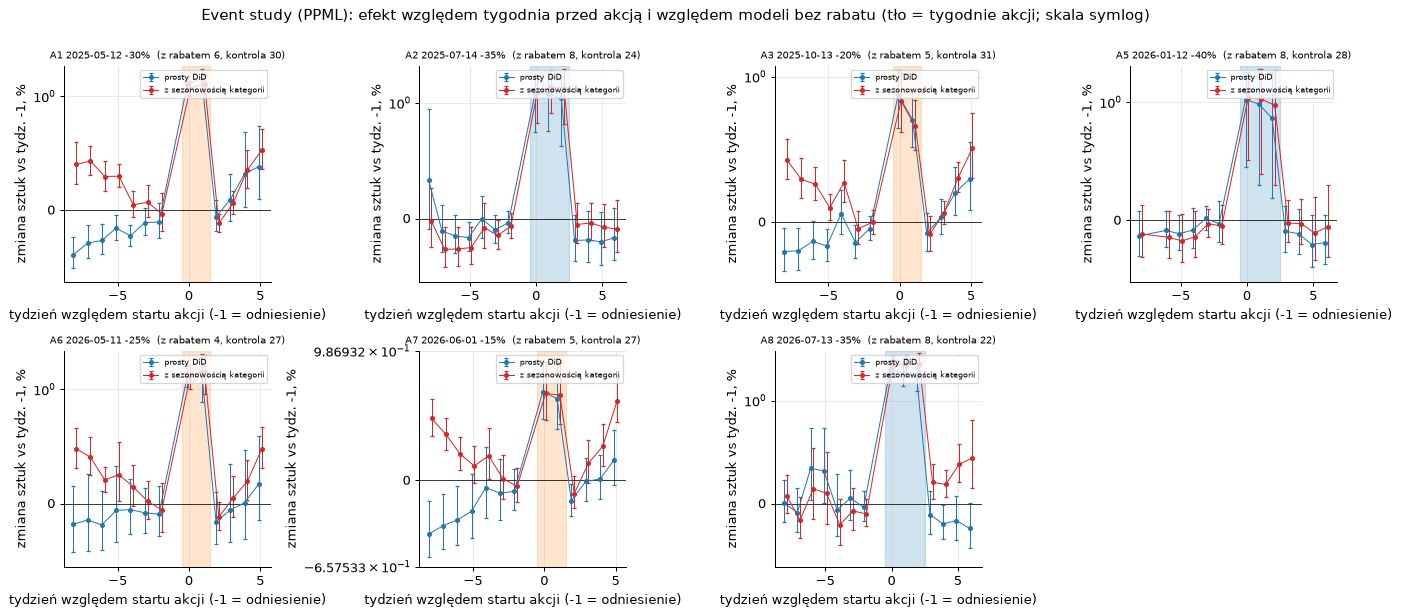

In [41]:
# Wykres event study: efekt (zmiana % sztuk względem tygodnia -1) modeli z akcji vs kontrola, dwa warianty kontroli.
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8), sharey=False)
for ax, (_, a) in zip(axes.ravel(), act_ns.iterrows()):
    n = int(a.Days // 7)
    for ESd, col, lab in ((ES_ALL, "C0", "prosty DiD"), (ES_HARM, "C3", "z sezonowością kategorii")):
        es = ESd[a.Id]
        se = np.sqrt(np.diag(es["V"]))
        x = es["rels"] + (0.1 if col == "C3" else -0.1)
        ax.errorbar(x, np.exp(es["b"]) - 1, yerr=[np.exp(es["b"]) - np.exp(es["b"] - 1.96 * se), np.exp(es["b"] + 1.96 * se) - np.exp(es["b"])],
                    fmt="o-", ms=3, lw=.8, capsize=1.5, color=col, label=lab)
    ax.axvspan(-.5, n - .5, color=type_color[a.Typ], alpha=.2); ax.axhline(0, color="k", lw=.6)
    ax.set_title(f"{a.Id} {a.Start.date()} -{int(a.DiscPct)}%  (z rabatem {ES_ALL[a.Id]['n_tr']}, kontrola {ES_ALL[a.Id]['n_ctrl']})", fontsize=8)
    ax.set_xlabel("tydzień względem startu akcji (-1 = odniesienie)"); ax.set_ylabel("zmiana sztuk vs tydz. -1, %")
    ax.set_yscale("symlog", linthresh=1)
    ax.legend(fontsize=6, loc="upper right")
axes.ravel()[-1].axis("off")
fig.suptitle("Event study (PPML): efekt względem tygodnia przed akcją i względem modeli bez rabatu (tło = tygodnie akcji; skala symlog)", y=1.0)
plt.tight_layout(); plt.show()

### Testy H2 i H3 (progi zapisane w sekcji 7)

**Doprecyzowanie H2 przed obliczeniem.** „Akcja w szczycie sezonowym" operacjonalizuję tak: sprzedaż tygodniowa modeli akcji (oba kanały) w 4 tygodniach *przed* startem, podzielona przez ich średnią sprzedaż tygodniową z całego okresu danych, jest większa niż 1. Akcje spoza tej grupy to „poza szczytem". Miara H2 to różnica uplift: naiwny M0 minus M1, w punktach procentowych, zbiorczo dla akcji w szczycie (oba kanały razem), przedział z tych samych 300 losowań modeli co M1 (różnica jest sparowana). **Próg: ≥10 pp i przedział 95% powyżej 0.**

**H3 (zapisana wcześniej):** efekt w tygodniach +1 i +2 po akcji < 0 z przedziałem 95% w całości poniżej 0 **oraz** udział przesunięcia (sztuki „brakujące" po akcji / sztuki dodatkowe w akcji) co najmniej 10%. Zbiorczo dla akcji A1-A3, A5-A8 (BF osobno, bo bez kontroli).

In [42]:
pre_idx = {}
for _, a in act_ns.iterrows():
    tr = list(ep[ep.Id == a.Id].StyleCode.unique())
    pre4 = Pall_q[Pall_q.StyleCode.isin(tr) & Pall_q.WeekStart.isin([a.Start - pd.Timedelta(weeks=k) for k in range(1, 5)])]
    full = Pall_q[Pall_q.StyleCode.isin(tr)]
    pre_idx[a.Id] = pre4.Qty.mean() / full.Qty.mean()
PEAK = pd.Series(pre_idx).rename("sprzedaz_przed/srednia")
peak_ids = [i for i in PEAK.index if PEAK[i] > 1]
print("Indeks sprzedaży 4 tyg. przed akcją (średnia całego okresu = 1):"); print(PEAK.round(2).to_string())
print("Akcje w szczycie (>1):", peak_ids, "| poza szczytem:", [i for i in PEAK.index if i not in peak_ids])

def m0_pooled(ids, arr):
    sel = [act_ns.index[act_ns.Id == i][0] for i in ids]
    a_ = arr[..., sel, :]
    return (a_[..., 0].sum(-1) / a_[..., 1].sum(-1)) / (a_[..., 2].sum(-1) / a_[..., 3].sum(-1)) - 1

M0_pt = M0_arr.sum(axis=2)                                           # estymata punktowa (wszystkie modele, mnożnik 1)
rows = []
for lab, ids in (("akcje w szczycie", peak_ids), ("akcje poza szczytem", [i for i in PEAK.index if i not in peak_ids]), ("wszystkie bez BF", list(PEAK.index))):
    m0_d = np.concatenate([[m0_pooled(ids, M0_pt)], m0_pooled(ids, m0_draws)])
    m1_d = summ(aid=ids)["uplift_akcja"]
    diff = 100 * (m0_d - m1_d)
    pt, lo, hi = pci(diff)
    rows.append(dict(grupa=lab, akcje=",".join(ids), uplift_M0=m0_d[0], uplift_M1=m1_d[0], roznica_pp=pt, lo_pp=lo, hi_pp=hi))
H2T = pd.DataFrame(rows)
print("\nH2: różnica uplift M0 - M1 (pp), oba kanały razem:"); print(H2T.round(2).to_string(index=False))
r2 = H2T.iloc[0]
h2 = "potwierdzona" if (r2.roznica_pp >= 10 and r2.lo_pp > 0) else "odrzucona"
register("H2", "uplift M0 minus M1, akcje w szczycie (sparowany bootstrap)", f"{r2.roznica_pp:+.1f} pp", f"95% [{r2.lo_pp:+.1f}; {r2.hi_pp:+.1f}]", h2)
print("Decyzja H2:", h2)

# H3 zbiorczo
rows = []
for lab, ch in (("oba kanały", None), ("sklepy", "STORE"), ("online", "ONLINE")):
    o = summ(ch=ch)
    e, elo, ehi = pci(o["efekt_po"]); s_, slo, shi = pci(o["udzial_przesun"]); un, nlo, nhi = pci(o["uplift_netto"]); u, ulo, uhi = pci(o["uplift_akcja"])
    rows.append(dict(zakres=lab, uplift_w_akcji=u, up_lo=ulo, up_hi=uhi, efekt_po_akcji=e, po_lo=elo, po_hi=ehi, udzial_przesuniecia=s_, sh_lo=slo, sh_hi=shi, uplift_netto=un))
H3T = pd.DataFrame(rows)
print("\nH3 (M1): efekt w tygodniach +1,+2 oraz udział przesunięcia popytu, akcje A1-A3, A5-A8:"); print(H3T.round(3).to_string(index=False))
r3 = H3T.iloc[0]
h3 = "potwierdzona" if (r3.po_hi < 0 and r3.udzial_przesuniecia >= 0.10) else ("niejednoznaczna" if r3.po_hi >= 0 else "odrzucona (udział < 10%)")
register("H3", "efekt w tygodniach +1,+2 (M1, oba kanały) i udział przesunięcia", f"{r3.efekt_po_akcji:+.1%}; udział {r3.udzial_przesuniecia:.0%}", f"95% [{r3.po_lo:+.1%}; {r3.po_hi:+.1%}]", h3)
print("Decyzja H3:", h3)
# porównanie z M2 (event study z sezonowością): udział przesunięcia per akcja
cmp = pd.DataFrame({"Akcja": act_ns.Id,
                    "efekt_po_M1 (zbiorczo)": [summ(aid=i)["efekt_po"][0] for i in act_ns.Id],
                    "efekt_po_M2 prosty": [ES_ALL[i]["S"][0, 2] for i in act_ns.Id],
                    "efekt_po_M2 sezon.": [ES_HARM[i]["S"][0, 2] for i in act_ns.Id]})
cmp.round(3)

Indeks sprzedaży 4 tyg. przed akcją (średnia całego okresu = 1):
A1   0.880
A2   0.900
A3   1.200
A5   1.480
A6   0.870
A7   1.130
A8   1.140
Akcje w szczycie (>1): ['A3', 'A5', 'A7', 'A8'] | poza szczytem: ['A1', 'A2', 'A6']

H2: różnica uplift M0 - M1 (pp), oba kanały razem:
              grupa                akcje  uplift_M0  uplift_M1  roznica_pp   lo_pp   hi_pp
   akcje w szczycie          A3,A5,A7,A8      2.250      1.070     117.530  79.090 154.640
akcje poza szczytem             A1,A2,A6      1.420      1.280      14.730 -23.870  57.720
   wszystkie bez BF A1,A2,A3,A5,A6,A7,A8      1.880      1.140      74.270  41.350 105.610
Decyzja H2: potwierdzona

H3 (M1): efekt w tygodniach +1,+2 oraz udział przesunięcia popytu, akcje A1-A3, A5-A8:
    zakres  uplift_w_akcji  up_lo  up_hi  efekt_po_akcji  po_lo  po_hi  udzial_przesuniecia  sh_lo  sh_hi  uplift_netto
oba kanały           1.140  1.039  1.225          -0.120 -0.167 -0.074                0.082  0.047  0.122         0.590
    s

,Akcja,efekt_po_M1 (zbiorczo),efekt_po_M2 prosty,efekt_po_M2 sezon.
0,A1,-0.119,0.017,-0.029
1,A2,-0.123,-0.186,-0.044
2,A3,-0.115,-0.014,-0.002
3,A5,-0.121,-0.102,-0.024
4,A6,-0.119,-0.109,-0.040
5,A7,-0.118,-0.075,0.022
6,A8,-0.123,-0.147,0.199


## 8.5 Faza 6, metoda M3: model gradientowy (kontrast, nie metoda do oceny efektu)

**Po co.** Zespół data science często zaczyna od „wrzućmy rabat jako cechę do LightGBM". Pokazuję to jako **kontrast**: model gradientowy świetnie *przewiduje sprzedaż*, ale pytanie zleceniodawcy jest inne: *co by się stało, gdyby rabatu nie było*. Model nie wie, że rabat bywa nadawany w sezonie i na słabe modele; jeśli cechy (tydzień roku, model, kategoria) wyjaśniają sprzedaż równie dobrze, wpływ cechy rabatu bywa przeszacowany albo zaniżony w sposób, którego nie widać w błędzie predykcji.

**Konstrukcja.** LightGBM z funkcją straty Poissona (sztuki). Cechy: stopa rabatu, kategoria, kanał, tydzień roku, model (kategoryjnie). Numeru tygodnia kalendarzowego **nie** podaję (nie byłby dostępny w przyszłości). Hiperparametry stałe (bez strojenia, żeby nie „dopasowywać" wyniku). Dwa zastosowania: (1) **wykres zależności cząstkowej** (PDP): średnia przewidywana sprzedaż przy rabacie $d$ względem rabatu 0, z tym samym wzorcem sezonowym; (2) uplift „implikowany": przewidywanie przy faktycznym rabacie vs przy rabacie 0 dla komórek akcji. Porównuję z M1.

M3 LightGBM, dopasowanie na całym panelu: korelacja obserwowane vs przewidywane = 0.960 (M1: 0.970) | uwaga: to dopasowanie w próbie, nie ocena predykcyjna


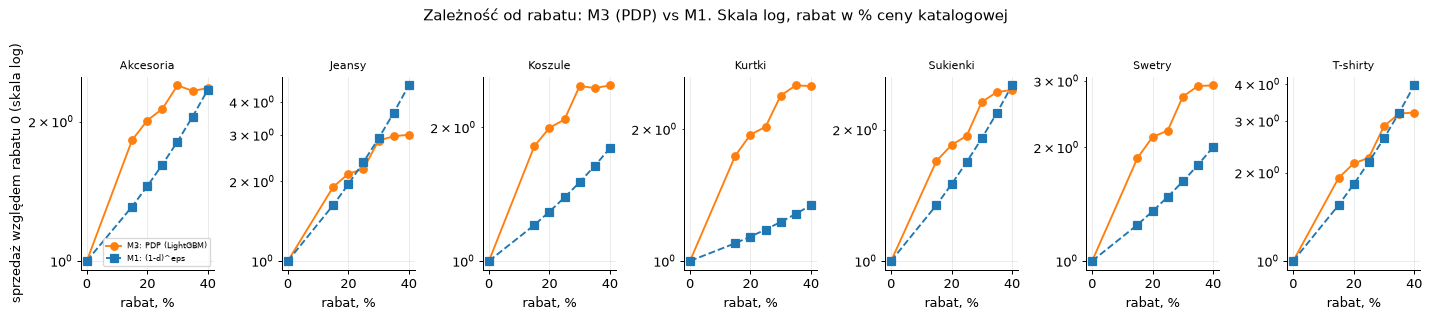

In [43]:
import lightgbm as lgb
cat_codes = {c: i for i, c in enumerate(sorted(Pm.Category.unique()))}
mod_codes = {m: i for i, m in enumerate(sorted(Pm.StyleCode.unique()))}
def feats(df, d=None):
    X = pd.DataFrame({"d": df.d.values if d is None else d, "cat": df.Category.map(cat_codes).values,
                      "ch": (df.Channel == "STORE").astype(int).values, "woy": df.woy.values, "model": df.StyleCode.map(mod_codes).values})
    return X
LGB_PARAMS = dict(objective="poisson", n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.9, random_state=SEED, verbose=-1, n_jobs=2)
Xall = feats(Pm)
m3 = lgb.LGBMRegressor(**LGB_PARAMS).fit(Xall, Pm.Qty, categorical_feature=["cat", "model"])
pred = m3.predict(Xall)
print(f"M3 LightGBM, dopasowanie na całym panelu: korelacja obserwowane vs przewidywane = {np.corrcoef(Pm.Qty, pred)[0, 1]:.3f} (M1: {np.corrcoef(f_cc['y'], f_cc['mu'])[0, 1]:.3f}) | uwaga: to dopasowanie w próbie, nie ocena predykcyjna")

# PDP względem rabatu 0, osobno kategorie; porównanie z M1 (elastyczność kategorii ze specyfikacji "cat", kanał STORE)
f_cat0 = D_cat.fit()
eps_cat = dict(zip(D_cat.cats, f_cat0["b"][D_cat.ti][:len(D_cat.cats)]))
dg = np.array([0.0, .15, .20, .25, .30, .35, .40])
pdp = {}
base0 = None
for c in D_cat.cats:
    sub = Pm[Pm.Category == c]
    out = []
    for dv in dg:
        out.append(m3.predict(feats(sub, d=np.full(len(sub), dv))).mean())
    pdp[c] = np.array(out) / out[0]
fig, axes = plt.subplots(1, 7, figsize=(16, 3.4), sharey=False)
for ax, c in zip(axes, D_cat.cats):
    ax.plot(100 * dg, pdp[c], "o-", label="M3: PDP (LightGBM)", color="C1")
    ax.plot(100 * dg, (1 - dg) ** eps_cat[c], "s--", label="M1: (1-d)^eps", color="C0")
    ax.set_title(c, fontsize=9); ax.set_xlabel("rabat, %"); ax.set_yscale("log")
axes[0].set_ylabel("sprzedaż względem rabatu 0 (skala log)"); axes[0].legend(fontsize=6)
fig.suptitle("Zależność od rabatu: M3 (PDP) vs M1. Skala log, rabat w % ceny katalogowej", y=1.03)
plt.tight_layout(); plt.show()

In [44]:
# Uplift implikowany przez M3 w komórkach akcji (sklepy + online razem) i porównanie z M0 i M1
rows = []
for _, a in act_ns.iterrows():
    cc_ = cells[(cells.aid == a.Id) & (cells.faza == "akcja")]
    sub = Pm.merge(cc_[["StyleCode", "WeekStart", "Channel"]], on=["StyleCode", "WeekStart", "Channel"])
    with0 = m3.predict(feats(sub, d=np.zeros(len(sub)))).sum()
    withd = m3.predict(feats(sub)).sum()
    o = summ(aid=a.Id)
    rows.append(dict(Akcja=a.Id, rabat=a.DiscPct / 100, uplift_M0=M0[(M0.Akcja == a.Id) & (M0.kanal == "RAZEM")].uplift_naiwny.iloc[0],
                     uplift_M1=o["uplift_akcja"][0], uplift_M3_implikowany=withd / with0 - 1))
M3CMP = pd.DataFrame(rows)
print("Uplift w tygodniach akcji: M0 (naiwny), M1 (PPML z efektami stałymi), M3 (LightGBM, d vs d=0; implikowany):")
M3CMP.round(2)

Uplift w tygodniach akcji: M0 (naiwny), M1 (PPML z efektami stałymi), M3 (LightGBM, d vs d=0; implikowany):


,Akcja,rabat,uplift_M0,uplift_M1,uplift_M3_implikowany
0,A1,0.300,1.580,1.020,1.260
1,A2,0.350,1.470,1.410,1.660
2,A3,0.200,1.650,0.400,0.900
3,A5,0.400,2.430,1.030,1.510
4,A6,0.250,1.270,1.460,1.340
5,A7,0.150,1.260,0.590,0.950
6,A8,0.350,3.050,1.730,2.010


## 9. Faza 7: odporność wyników

**Po co.** Wyniki M1 i M2 mają sens tylko wtedy, gdy metoda nie „znajduje" efektów tam, gdzie ich nie ma, nie zależy od jednej decyzji modelarskiej i przewiduje coś, czego nie widziała. Cztery testy:

1. **Placebo:** fałszywe akcje (rabat 25% na 4 losowych modelach jednej kategorii przez 3 tygodnie), umieszczone w okresach, gdy te modele nie miały żadnej akcji. Skoro rabatu *nie było*, dobra metoda nie powinna znajdować efektu częściej niż w 5% przypadków (poziom istotności 0,05). Porównuję M1 z naiwnym M0.
2. **Zmiany specyfikacji i wyłączenia:** inna sezonowość, bez wskaźników tygodni po akcji, bez wskaźników BF, bez efektów stałych modelu, wyłączenie pojedynczej akcji lub kategorii.
3. **Predykcja poza próbą (jedna akcja wyłączona naraz):** elastyczność estymuję na pozostałych akcjach i przewiduję **sprzedaż w tygodniach wyłączonej akcji**. Porównuję z M0 (średni naiwny uplift pozostałych akcji) i M3 (LightGBM). Cel jest niezależny od modeli (prawdziwa sprzedaż).
4. **Wrażliwość wniosku o opłacalności** na horyzont dołka i wariant zwrotów.

In [45]:
# --- 1. Placebo ---
D_p = D_pool                                                              # jedna elastyczność na kanał; kolumna placebo dodana osobno
rows_all, X_base = D_p.matrix(np.arange(D_p.M), "model")
y_all = D_p.y
idx_of = {(m, w): i for i, (m, w) in enumerate(zip(Pm.StyleCode, Pm.WeekStart))}
busy = pd.DataFrame(False, index=DiscW.index, columns=models)
busy |= DiscW > 0
for r_ in post_cells.itertuples():
    busy.loc[r_.WeekStart, r_.StyleCode] = True
busy_pad = busy | busy.shift(1, fill_value=False) | busy.shift(-1, fill_value=False)       # margines 1 tydzień wokół prawdziwych akcji
wk_list = list(DiscW.index)
cat_models = {c: [m for m in models if cat_of[m] == c] for c in sorted(set(cat_of))}
PLA_N, FAKE_D, FAKE_W = 200, 0.25, 3
rP = np.random.default_rng(SEED + 7)
prow = []
tries = 0
while len(prow) < PLA_N and tries < 20000:
    tries += 1
    c = rP.choice(sorted(cat_models))
    ms = list(rP.choice(cat_models[c], size=min(4, len(cat_models[c])), replace=False))
    s0 = int(rP.integers(2, len(wk_list) - FAKE_W - 4))
    win = wk_list[s0 - 1: s0 + FAKE_W + 2]                                  # tydzień przed, 3 fałszywe, 2 po
    if busy_pad.loc[win, ms].values.any():
        continue
    fake_weeks = wk_list[s0: s0 + FAKE_W]
    fake = np.zeros(len(Pm))
    for m in ms:
        for w in fake_weeks:
            for chn in ("ONLINE", "STORE"):
                pass
    sel = Pm.StyleCode.isin(ms) & Pm.WeekStart.isin(fake_weeks)
    fake[sel.values] = np.log(1 - FAKE_D)
    X = np.hstack([X_base, fake[:, None]])
    b, mu, Ainv = PP.ppml(X, y_all)
    V = PP.cluster_cov(X, y_all - mu, Ainv, np.arange(D_p.M) * D_p.BLOCK)
    se = np.sqrt(V[-1, -1]); z = b[-1] / se
    # M0 na tych samych fałszywych tygodniach (oba kanały razem)
    g = Pall_q[Pall_q.StyleCode.isin(ms)]
    a_, r_ = g[g.WeekStart.isin(fake_weeks)].Qty, g[(g.d == 0) & ~g.WeekStart.isin(fake_weeks)].Qty
    prow.append(dict(kat=c, start=wk_list[s0].date(), minus_eps=-b[-1], z=z, p=2 * stats.norm.sf(abs(z)), uplift_M0=a_.mean() / r_.mean() - 1,
                     p_M0=stats.ttest_ind(a_, r_, equal_var=False).pvalue))
PLA = pd.DataFrame(prow)
fdr_m1 = ((PLA.p < .05) & (PLA.minus_eps > 0)).mean(); fdr_m0 = ((PLA.p_M0 < .05) & (PLA.uplift_M0 > 0)).mean()
print(f"Placebo: {len(PLA)} fałszywych akcji ({FAKE_W} tyg., rabat {FAKE_D:.0%}, 4 modele jednej kategorii).")
print(f"M1 (PPML): odsetek fałszywych odkryć (p<0,05 i dodatnia reakcja): {fdr_m1:.1%} | dwustronnie: {(PLA.p < .05).mean():.1%} | mediana -eps: {PLA.minus_eps.median():+.2f} (rozstęp 5-95%: {PLA.minus_eps.quantile(.05):+.2f}…{PLA.minus_eps.quantile(.95):+.2f})")
print(f"M0 (naiwny): odsetek fałszywych odkryć (Welch p<0,05 i uplift>0): {fdr_m0:.1%} | mediana „upliftu\": {PLA.uplift_M0.median():+.0%} (5-95%: {PLA.uplift_M0.quantile(.05):+.0%}…{PLA.uplift_M0.quantile(.95):+.0%})")
register("Faza 7", "placebo M1 (fałszywe akcje): odsetek fałszywych odkryć", f"{fdr_m1:.1%} ({len(PLA)} prób)", "oczekiwane ~2,5% (jednostronnie) / 5% (dwustronnie)", "ocena kalibracji")
register("Faza 7", "placebo M0 (naiwny): odsetek fałszywych odkryć", f"{fdr_m0:.1%} ({len(PLA)} prób)", "jw.", "naiwny test jest miarą nieskalibrowaną")

Placebo: 200 fałszywych akcji (3 tyg., rabat 25%, 4 modele jednej kategorii).
M1 (PPML): odsetek fałszywych odkryć (p<0,05 i dodatnia reakcja): 7.0% | dwustronnie: 14.5% | mediana -eps: -0.01 (rozstęp 5-95%: -0.64…+0.58)
M0 (naiwny): odsetek fałszywych odkryć (Welch p<0,05 i uplift>0): 5.0% | mediana „upliftu": -12% (5-95%: -58%…+34%)


In [46]:
# --- 2. Warianty specyfikacji i wyłączenia (elastyczność per kategoria, kanał STORE jako odniesienie, plus pojedyncze zbiorcze) ---
def fit_variant(label, dkw=None, fe="model", drop_rows=None, drop_cat=None):
    dkw = dkw or {}
    Dc = PP.Design(Pm, bf_start, post_cells, spec="cat", **dkw)
    Dp = PP.Design(Pm, bf_start, post_cells, spec="pooled", **dkw)
    out = {"wariant": label}
    keep = np.arange(Dc.M) if drop_cat is None else np.array([i for i, m in enumerate(Dc.models) if cat_of[m] != drop_cat])
    for D_, kind in ((Dc, "cat"), (Dp, "pooled")):
        rws, X = D_.matrix(keep, fe)
        yv = D_.y[rws]
        msk = np.ones(len(rws), bool)
        if drop_rows is not None:
            msk = ~np.isin(rws, drop_rows)
        b, _, _ = PP.ppml(X[msk], yv[msk])
        for j, n in zip(D_.ti, D_.treat_names):
            used = np.abs(X[msk][:, j]).sum() > 0
            out[n.replace("eps_", "")] = -b[j] if used else np.nan
    return out

Pm_ix = Pm.reset_index().rename(columns={"index": "row"})[["row", "StyleCode", "Channel", "WeekStart"]]
cells_r = cells.merge(Pm_ix, on=["StyleCode", "Channel", "WeekStart"])
var_rows = [fit_variant("główna (harmoniczne K=2, wskaźniki BF i po akcji)")]
var_rows.append(fit_variant("harmoniczne K=1", dict(harmonics=1)))
var_rows.append(fit_variant("harmoniczne K=3", dict(harmonics=3)))
var_rows.append(fit_variant("bez sezonowości kategorii", dict(cat_season=False)))
var_rows.append(fit_variant("bez wskaźników po akcji", dict(post=False)))
var_rows.append(fit_variant("bez wskaźników BF", dict(bf_ind=False)))
var_rows.append(fit_variant("bez efektów stałych modelu (kategoria x kanał)", fe="cat"))
for _, a in act_ns.iterrows():
    var_rows.append(fit_variant(f"bez akcji {a.Id}", drop_rows=cells_r[cells_r.aid == a.Id].row.values))
for c in sorted(cat_models):
    var_rows.append(fit_variant(f"bez kategorii {c}", drop_cat=c))
VAR = pd.DataFrame(var_rows).set_index("wariant")
keep_cols = [c for c in VAR.columns if not c.startswith("online_shift") and c not in ("ONLINE", "STORE")] + ["STORE", "ONLINE"]
print("Siła reakcji -eps (kategoria: wspólna dla kanałów; STORE/ONLINE: jedna elastyczność na kanał) w wariantach specyfikacji:")
VAR[keep_cols].round(2)

Siła reakcji -eps (kategoria: wspólna dla kanałów; STORE/ONLINE: jedna elastyczność na kanał) w wariantach specyfikacji:


,Akcesoria,Jeansy,Koszule,Kurtki,Sukienki,Swetry,T-shirty,STORE,ONLINE
wariant,,,,,,,,,
"główna (harmoniczne K=2, wskaźniki BF i po akcji)",1.660,3.000,1.150,0.570,1.810,1.360,2.700,1.780,2.430
harmoniczne K=1,1.610,3.050,1.090,0.540,1.810,1.340,2.740,1.770,2.430
harmoniczne K=3,1.690,2.950,1.090,0.570,1.850,1.430,2.640,1.780,2.430
bez sezonowości kategorii,1.500,3.070,1.160,1.710,3.100,2.450,4.110,2.670,3.320
bez wskaźników po akcji,1.670,3.010,1.150,0.590,1.830,1.390,2.740,1.800,2.450
bez wskaźników BF,1.660,2.980,1.140,0.600,1.810,1.360,2.700,1.780,2.430
bez efektów stałych modelu (kategoria x kanał),1.580,2.590,0.680,-0.050,1.230,0.500,2.410,1.280,1.960
bez akcji A1,1.670,3.000,1.140,0.580,1.770,1.360,2.690,1.760,2.410
bez akcji A2,2.280,3.010,0.980,0.600,1.750,1.370,2.630,1.760,2.440


In [47]:
# --- 3. Predykcja poza próbą (leave-one-action-out) ---
X_all, y_hold_all = X_base[:, :D_cc.B.shape[1]], None
rows_cc, X_cc = D_cc.matrix(np.arange(D_cc.M), "model")
tcols = D_cc.ti + D_cc.pi
M0_other = M0[(M0.kanal == "RAZEM") & M0.Akcja.isin(act_ns.Id)].set_index("Akcja").uplift_naiwny
ref_mean = Pm[Pm.d == 0].groupby(["StyleCode", "Channel"]).Qty.mean()
rows = []
for _, a in act_ns.iterrows():
    hold = cells_r[(cells_r.aid == a.Id) & (cells_r.faza == "akcja")].row.values
    hold_all = cells_r[cells_r.aid == a.Id].row.values
    msk = np.ones(len(y_all), bool); msk[hold_all] = False
    b, mu, _ = PP.ppml(X_cc[msk], D_cc.y[msk])
    bt = b.copy()
    ti = D_cc.ti
    for jj, j in enumerate(ti):
        if np.abs(X_cc[msk][:, j]).sum() == 0:                              # kategoria bez innej akcji: elastyczność średnia z pozostałych kategorii tego kanału
            same = [b[ti[k]] for k in range(len(ti)) if k % 2 == jj % 2 and np.abs(X_cc[msk][:, ti[k]]).sum() > 0]
            bt[j] = np.mean(same)
    for j in D_cc.pi:
        if np.abs(X_cc[msk][:, j]).sum() == 0:
            bt[j] = 0.0
    b_no = bt.copy(); b_no[tcols] = 0
    eta_w, eta_n = X_cc[hold] @ bt, X_cc[hold] @ b_no
    y_h = D_cc.y[hold].sum()
    pred_m1 = np.exp(eta_w).sum()
    obs_up = y_h / np.exp(eta_n).sum() - 1
    pred_up_m1 = pred_m1 / np.exp(eta_n).sum() - 1
    # M3 na wyłączonej próbie
    m3_h = lgb.LGBMRegressor(**LGB_PARAMS).fit(feats(Pm[msk]), Pm.Qty[msk], categorical_feature=["cat", "model"])
    sub = Pm.loc[hold]
    pred_m3 = m3_h.predict(feats(sub)).sum()
    # M0: średnia z modeli bez rabatu x (1 + średni naiwny uplift innych akcji)
    u_bar = M0_other.drop(a.Id).mean()
    pred_m0 = sum(ref_mean[(r_.StyleCode, r_.Channel)] * (1 + u_bar) for r_ in sub.itertuples())
    rows.append(dict(Akcja=a.Id, obserwowane_szt=y_h, M0_blad=pred_m0 / y_h - 1, M1_blad=pred_m1 / y_h - 1, M3_blad=pred_m3 / y_h - 1,
                     uplift_obs_wzgl_kontrfaktu=obs_up, uplift_przew_M1=pred_up_m1))
LOAO = pd.DataFrame(rows)
print("Predykcja poza próbą: błąd względny przewidzianej sprzedaży w tygodniach wyłączonej akcji (przewidziane / obserwowane - 1):")
print(LOAO.round(3).to_string(index=False))
mae = {m: LOAO[m].abs().mean() for m in ("M0_blad", "M1_blad", "M3_blad")}
print("Średni bezwzględny błąd względny:", {k: f"{v:.1%}" for k, v in mae.items()})
for m_, v_ in mae.items():
    register("Faza 7", f"leave-one-action-out: średni |błąd| przewidzianej sprzedaży ({m_[:2]})", f"{v_:.1%}", "7 akcji (bez BF)", "porównanie metod")

Predykcja poza próbą: błąd względny przewidzianej sprzedaży w tygodniach wyłączonej akcji (przewidziane / obserwowane - 1):
Akcja  obserwowane_szt  M0_blad  M1_blad  M3_blad  uplift_obs_wzgl_kontrfaktu  uplift_przew_M1
   A1        4,731.000    0.100   -0.050   -0.105                       1.091            0.987
   A2        7,489.000    0.167    0.065    0.397                       1.389            1.544
   A3        3,622.000    0.069   -0.137    0.012                       0.570            0.355
   A5        7,755.000   -0.210    0.493   -0.092                       1.068            2.088
   A6        2,546.000    0.280   -0.011   -0.134                       1.486            1.459
   A7        3,064.000    0.281    0.062    0.094                       0.496            0.588
   A8       11,585.000   -0.356    0.084   -0.260                       1.599            1.816
Średni bezwzględny błąd względny: {'M0_blad': '20.9%', 'M1_blad': '12.9%', 'M3_blad': '15.6%'}


In [48]:
# --- 4. Wrażliwość werdyktu o opłacalności ---
n_t = len(D_cc.ti)
def imp_matrix(coefs, variant="A", post_mult=1.0):
    c2 = coefs.copy(); c2[:, n_t:] *= post_mult
    d_ = draws_from(c2)
    cfm = {"A": d_["CFA"], "B": d_["CFB"], "S": d_["CFA"]}[variant]
    obs = {"A": const["MA"], "B": const["MB"], "S": const["MS"]}[variant]
    return obs[None, :] - cfm

def verdict(lo, hi):
    return "opłaca się" if lo > 0 else ("nie opłaca się" if hi < 0 else "niejednoznaczne")

def cat_ch_table(impm, phases=("akcja", "po")):
    rows = []
    for c in cats_sorted:
        for ch in ("STORE", "ONLINE"):
            m = (~is_bf_key) & (keytab.Category == c).values & (keytab.Channel == ch).values & keytab.faza.isin(phases).values
            pt, lo, hi = pci(impm[:, m].sum(axis=1))
            rows.append(dict(kategoria=c, kanal=ch, wplyw_PLN=pt, lo=lo, hi=hi, werdykt=verdict(lo, hi)))
    return pd.DataFrame(rows)

SENS = {}
SENS["A: akcja + 2 tyg. (główny)"] = cat_ch_table(imp_matrix(coefs_all, "A"))
SENS["B: towar zwrócony wraca po koszcie"] = cat_ch_table(imp_matrix(coefs_all, "B"))
SENS["S: słownik (zwroty przyjęte w okresie)"] = cat_ch_table(imp_matrix(coefs_all, "S"))
SENS["A: tylko tygodnie akcji (bez dołka)"] = cat_ch_table(imp_matrix(coefs_all, "A"), phases=("akcja",))
SENS["A: dołek 2x głębszy (okno ok. 4 tyg.)"] = cat_ch_table(imp_matrix(coefs_all, "A", post_mult=2.0))
sens_tab = pd.DataFrame({k: v.werdykt for k, v in SENS.items()})
sens_tab.insert(0, "kanal", SENS["A: akcja + 2 tyg. (główny)"].kanal); sens_tab.insert(0, "kategoria", SENS["A: akcja + 2 tyg. (główny)"].kategoria)
print("Werdykt (reguła: przedział 95% wpływu na marżę w całości > 0 / < 0) w wariantach założeń:")
sens_tab.to_string(index=False)

Werdykt (reguła: przedział 95% wpływu na marżę w całości > 0 / < 0) w wariantach założeń:


'kategoria  kanal A: akcja + 2 tyg. (główny) B: towar zwrócony wraca po koszcie S: słownik (zwroty przyjęte w okresie) A: tylko tygodnie akcji (bez dołka) A: dołek 2x głębszy (okno ok. 4 tyg.)\nAkcesoria  STORE             nie opłaca się                     nie opłaca się                         nie opłaca się                      nie opłaca się                        nie opłaca się\nAkcesoria ONLINE             nie opłaca się                    niejednoznaczne                         nie opłaca się                      nie opłaca się                        nie opłaca się\n   Jeansy  STORE                 opłaca się                         opłaca się                             opłaca się                          opłaca się                       niejednoznaczne\n   Jeansy ONLINE                 opłaca się                         opłaca się                             opłaca się                          opłaca się                            opłaca się\n  Koszule  STORE             nie o